# Extreme Value Theory for Tail Risk: the S&P 500, 1928–2026

**Project 7 of the *Financial Risk Forecasting* series** (Daníelsson, Chapter 9, used as a guide only).

**Business question.** How large can a one-day loss on an S&P 500 position be at the 99.9% level (a loss seen about once every four years) and beyond — once in 10 or 100 years — and which model forecasts such losses reliably, day by day, out of sample?

**Data.** S&P 500 price index (Yahoo Finance, `^GSPC`), daily closes from 30 December 1927 to 27 October 2026 — 24,818 daily losses after the removal of four data errors. Downloaded from scratch.

**Methods.** Hill estimator; peaks over threshold with the Generalized Pareto Distribution (GPD); VaR and ES at 99–99.9% and for return periods of 10 and 100 years, against normal, Student-t and historical benchmarks; confidence intervals (delta method, profile likelihood, block bootstrap, coverage simulation); extremal index; **McNeil–Frey** (GJR-GARCH filter + GPD on the residuals), run out of sample from 1931 to 2026 and backtested with Kupiec, Christoffersen, exact binomial and Acerbi–Székely Z2 tests.

**Convention.** Losses are positive: $x_t = -100\,\ln(S_t/S_{t-1})$ in %. The equation numbers refer to the theory notes (`Project7_Theory_Notes.docx`).

| Section | Content |
|---|---|
| 1 | Data: download, quality checks, data errors, losses |
| 2 | The tails in the data |
| 3 | The Hill estimator |
| 4 | Peaks over threshold: choosing the threshold, fitting the GPD |
| 5 | Extreme VaR and ES: EVT against the benchmarks |
| 6 | How sure are we? Confidence intervals |
| 7 | Clustering of extremes and the GARCH filter |
| 8 | McNeil–Frey out of sample |
| 9 | Backtests, diagnosis and the fix |
| 10 | Conclusions |

Each step starts with the five problem-solving questions; each section ends with its findings.

## 1. Data

One free series, almost a century long. Before any tail is measured, the data must be right: a single mistyped close creates a fake −10% day, and in tail estimation one fake extreme matters a lot.

### 1.1 Setup

| | |
|---|---|
| **1. What do I need to determine?** | A working environment: all imports, the project paths and display options. |
| **2. What information and assumptions do I have?** | Notebook in `notebooks/`, package in `src/tailrisk`, folders `data/raw`, `data/processed`, `reports/figures`. |
| **3. Which method is appropriate?** | Add `src` to the Python path, then import every function once, here (package imports always after `sys.path.insert`). |
| **4. Why should the method work?** | One place for imports makes the notebook reproducible from top to bottom; autoreload picks up edits in the modules. |
| **5. How can I verify the answer?** | The three folders print `exists: True`. |

In [ ]:
# 1.1 Setup: imports, paths, display options
%load_ext autoreload
%autoreload 2

import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from arch import arch_model                  # only to cross-check our GJR-GARCH fit (Step 7.2)

ROOT = Path.cwd().parent                     # project folder (the notebook is in notebooks/)
sys.path.insert(0, str(ROOT / "src"))        # so that "import tailrisk" works

# package imports: always AFTER sys.path.insert
from tailrisk.data import load_yahoo, suspect_reversals, clean_closes, losses
from tailrisk.descriptive import ERAS, tail_table, ljung_box
from tailrisk.evt import (hill, hill_var_es, mean_excess, fit_gpd, threshold_stability, gpd_var_es,
                          gpd_var_ci, gpd_var_profile_ci, bootstrap_var_es, extremal_index_runs)
from tailrisk.benchmarks import fit_t, var_es_normal, var_es_t, var_es_hist
from tailrisk.garch import gjr_variance, fit_gjr_qml, standardised_residuals
from tailrisk.engine import LEVELS, METHODS, residual_var_es, rolling_tail_var, expanding_tail_var
from tailrisk.backtest import (kupiec_test, christoffersen_test, binomial_pvalue, acerbi_szekely_z2,
                               z2_critical, backtest_table)
from tailrisk.plots import (plot_qq, plot_hill, plot_mean_excess, plot_stability, plot_gpd_fit,
                            plot_return_levels, plot_backtest_summary, plot_var_through_crises)

warnings.filterwarnings("ignore", message=".*inplace keyword.*")      # harmless yfinance/pandas warning

RAW = ROOT / "data" / "raw"                  # downloads
OUT = ROOT / "data" / "processed"            # results we compute
FIGURES = ROOT / "reports" / "figures"       # saved charts

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

for p in [RAW, OUT, FIGURES]:
    print(f"{str(p):70s} exists: {p.exists()}")

C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_7Ad\evt-tail-risk\data\raw exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_7Ad\evt-tail-risk\data\processed exists: True
C:\Users\xps\Desktop\Quant_Risk_PM_CIO\Phase -0- Quant_Risk\Project_7Ad\evt-tail-risk\reports\figures exists: True


### 1.2 Test the Yahoo download on the S&P 500 since 1927

| | |
|---|---|
| **1. What do I need to determine?** | Does `load_yahoo` return the full daily history of the index? |
| **2. What information and assumptions do I have?** | Yahoo ticker `^GSPC` (price index, no dividends); its history starts on 30 December 1927. |
| **3. Which method is appropriate?** | Download the close, remove the time zone, drop missing values. |
| **4. Why should the method work?** | A price index is what a position in index futures or an ETF (excluding dividends) gains or loses each day. |
| **5. How can I verify the answer?** | Known facts: −20.47% on 19 October 1987, −9.03% on 15 October 2008, −11.98% on 16 March 2020; no missing values. |

In [ ]:
# 1.2 Test the Yahoo download on the S&P 500 since 1927
spx_test = load_yahoo("^GSPC")
r_test = spx_test.pct_change().dropna()                              # simple daily return

print(f"{len(spx_test):,} days, {spx_test.index[0].date()} to {spx_test.index[-1].date()}, "
      f"\nmissing values: {spx_test.isna().sum()}")
print(f"First close {spx_test.iloc[0]:.2f}, last close {spx_test.iloc[-1]:,.2f}")
for d in ["1987-10-19", "2008-10-15", "2020-03-16"]:
    print(f"Return on {d}: {r_test.loc[d]:+.2%}")
print("\n10 worst days (%):")
print((100 * r_test.nsmallest(10)).round(2).to_string())

24,823 days, 1927-12-30 to 2026-10-27, 
missing values: 0
First close 17.66, last close 7,722.60
Return on 1987-10-19: -20.47%
Return on 2008-10-15: -9.03%
Return on 2020-03-16: -11.98%

10 worst days (%):
date
1987-10-19   -20.47
1929-10-28   -12.94
2020-03-16   -11.98
1929-10-29   -10.16
1935-04-16    -9.97
1929-11-06    -9.92
1946-09-03    -9.91
2020-03-12    -9.51
1937-10-18    -9.12
1931-10-05    -9.07


### 1.3 Save the raw data and check its quality

| | |
|---|---|
| **1. What do I need to determine?** | Is the history usable: calendar, stale prices, suspicious moves? |
| **2. What information and assumptions do I have?** | Old data (1920s–1950s) were typed by hand; the NYSE also traded on Saturdays until 1952. |
| **3. Which method is appropriate?** | Save to `data/raw` once and reload afterwards; count days per weekday and per year, zero changes, and large moves reversed the next day. |
| **4. Why should the method work?** | A data error typically shows as a large move fully undone the next day, with both neighbours consistent. |
| **5. How can I verify the answer?** | Explain every anomaly: no Saturdays (Yahoo omits them), 12-day gap in March 1933 (bank holiday), September 2001 (markets closed). |

In [ ]:
# 1.3 Save the raw data, then check its quality: calendar, stale prices, reversals
raw_file = RAW / "spx.csv"
if raw_file.exists():
    spx = pd.read_csv(raw_file, index_col=0, parse_dates=True).iloc[:, 0]
    print("Loaded from data/raw")
else:
    spx = spx_test.copy()
    spx.to_csv(raw_file)
    print("Saved to data/raw/spx.csv")

r = spx.pct_change().dropna()                                       # simple daily return

# (1) Calendar: weekdays, days per year, gaps
print("\nTrading days per weekday (0 = Monday, 5 = Saturday):")
print(spx.index.day_of_week.value_counts().sort_index().to_string())
sat = spx.index[spx.index.day_of_week == 5]
if len(sat):
    print(f"Saturdays: {len(sat)}, from {sat[0].date()} to {sat[-1].date()}")
per_year = spx.groupby(spx.index.year).size()
print(f"\nDays per year: min {per_year.min()} ({per_year.idxmin()}), max {per_year.max()} ({per_year.idxmax()})")
print(per_year.loc[[1928, 1930, 1950, 1951, 1952, 1953, 1960, 2000, 2025]].to_string())
gaps = spx.index.to_series().diff().dt.days
print("\nLongest gaps between two closes (calendar days):")
print(gaps.nlargest(5).to_string())

# (2) Stale prices: zero changes, and the longest run of them
zero = (r == 0)
runs = zero.groupby((~zero).cumsum()).sum()
print(f"\nDays with zero change: {zero.sum()} ({zero.mean():.2%}); longest run: {runs.max()} days")
print("Zero changes by decade:")
print(zero.groupby((zero.index.year // 10) * 10).sum().to_string())

# (3) Reversals: |move| > 5% and the next day undoes more than 80% of it
nxt = r.shift(-1)
rev = (r.abs() > 0.05) & (np.sign(nxt) == -np.sign(r)) & (nxt.abs() > 0.8 * r.abs())
print(f"\nLarge moves (>5%) almost reversed the next day: {rev.sum()}")
print(pd.DataFrame({"return %": 100 * r[rev], "next day %": 100 * nxt[rev]}).round(2).to_string())

# (4) The two suspicious dates and their neighbours
for d in ["1935-04-16", "1946-09-03"]:
    i = spx.index.get_loc(pd.Timestamp(d))
    w = spx.iloc[i - 3:i + 4]
    print(f"\nAround {d}:")
    print(pd.DataFrame({"close": w, "return %": 100 * w.pct_change()}).round(2).to_string())

Loaded from data/raw

Trading days per weekday (0 = Monday, 5 = Saturday):
date
0    4774
1    5044
2    5060
3    4983
4    4962

Days per year: min 1 (1927), max 254 (1970)
date
1928    250
1930    251
1950    249
1951    249
1952    250
1953    251
1960    252
2000    252
2025    250

Longest gaps between two closes (calendar days):
date
1933-03-15    12.0
2001-09-17     7.0
1929-12-02     5.0
1945-12-26     5.0
1956-12-26     5.0

Days with zero change: 313 (1.26%); longest run: 3 days
Zero changes by decade:
date
1920      8
1930     48
1940    132
1950     67
1960     29
1970     18
1980      6
1990      2
2000      2
2010      1
2020      0

Large moves (>5%) almost reversed the next day: 20
            return %  next day %
date                            
1929-10-29    -10.16       12.53
1929-10-31      5.05       -5.26
1929-11-13     -5.71        8.95
1931-01-07     -6.45        7.55
1931-09-23      6.67       -7.29
1931-10-05     -9.07       12.36
1932-10-10     -8.55        

### 1.4 Data errors: reversed moves measured against recent volatility

| | |
|---|---|
| **1. What do I need to determine?** | Which of the 20 large reversals are data errors and which are real crisis days? |
| **2. What information and assumptions do I have?** | A real reversal happens when volatility is already high (1929, 2008, 2020); an error is huge compared with a calm market. |
| **3. Which method is appropriate?** | `suspect_reversals`: z = move / volatility of the previous 60 days; suspect if |z| > 6 and reversed by more than 80%. |
| **4. Why should the method work?** | Scaling by volatility separates 'large for the time' from 'large in absolute terms' — the same −9% is normal in 1932 and impossible in a calm 1935. |
| **5. How can I verify the answer?** | Look at the closes around each suspect: one isolated close out of line, the days before and after consistent. |

In [ ]:
# 1.4 Data errors: reversed moves measured against the volatility of the previous 60 days
sus = suspect_reversals(spx)
print(sus.round(2).to_string())
print(f"\nSuspect days (|z| > 6): {sus['suspect'].sum()}")

for d in sus.index[sus["suspect"]]:
    i = spx.index.get_loc(d)
    w = spx.iloc[i - 3:i + 4]
    print(f"\nAround {d.date()}:")
    print(pd.DataFrame({"close": w, "return %": 100 * w.pct_change()}).round(2).to_string())

            return %  next day %  vol before %     z  z next  suspect
date                                                                 
1929-10-29    -10.16       12.53          2.54 -4.00    4.93    False
1929-10-31      5.05       -5.26          3.30  1.53   -1.59    False
1929-11-13     -5.71        8.95          3.75 -1.52    2.38    False
1931-01-07     -6.45        7.55          2.11 -3.05    3.57    False
1931-09-23      6.67       -7.29          1.79  3.72   -4.07    False
1931-10-05     -9.07       12.36          2.28 -3.98    5.42    False
1932-10-10     -8.55        7.17          4.04 -2.12    1.77    False
1932-11-07      5.23       -4.42          4.06  1.29   -1.09    False
1933-07-21     -8.70        8.81          3.11 -2.80    2.84    False
1935-04-16     -9.97        9.61          1.27 -7.87    7.59     True
1935-05-16     -6.82        9.40          2.22 -3.08    4.24    False
1935-08-16     -7.97        7.53          1.04 -7.69    7.27     True
1936-09-16     -5.84

### 1.5 Remove the bad closes and save the clean series

| | |
|---|---|
| **1. What do I need to determine?** | A clean close series, and proof that nothing else changed. |
| **2. What information and assumptions do I have?** | `BAD_CLOSES` lists four dates: the three found in 1.4 and 1961-04-17, found by the second pass in Step 7.5. |
| **3. Which method is appropriate?** | `clean_closes` drops those closes; the return across the gap becomes one correct return. |
| **4. Why should the method work?** | Dropping the wrong close (rather than inventing a value) keeps every other price as published. |
| **5. How can I verify the answer?** | The joined returns are small (−1.31%, −1.04%, −0.38%); no suspects left; the crisis days are unchanged. |

In [ ]:
# 1.5 Remove the bad closes (BAD_CLOSES: the three found in 1.4 + the one found in 7.5), check, save
spx_clean = clean_closes(spx)
r_clean = spx_clean.pct_change().dropna()

print(f"Closes: {len(spx)} -> {len(spx_clean)}")
print("\nThe joined returns that replace each bad pair:")
for d in pd.to_datetime(["1935-04-17", "1935-08-19", "1936-09-17"]):
    print(f"{d.date()}: {100 * r_clean.loc[d]:+.2f}%  (before: {100 * r.loc[d]:+.2f}% after {100 * r.shift(1).loc[d]:+.2f}%)")

left = suspect_reversals(spx_clean)
print(f"\nReversals left: {len(left)}, suspect: {left['suspect'].sum()}")
print(f"Crisis days unchanged: {np.allclose(r_clean.loc[['1929-10-28', '1987-10-19', '2020-03-16']], r.loc[['1929-10-28', '1987-10-19', '2020-03-16']])}")

spx_clean.to_csv(OUT / "spx_clean.csv")
print("\nSaved data/processed/spx_clean.csv")

Closes: 24823 -> 24819

The joined returns that replace each bad pair:
1935-04-17: -1.31%  (before: +9.61% after -9.97%)
1935-08-19: -1.04%  (before: +7.53% after -7.97%)
1936-09-17: -0.38%  (before: +5.80% after -5.84%)

Reversals left: 17, suspect: 0
Crisis days unchanged: True

Saved data/processed/spx_clean.csv


### 1.6 Daily losses in % (Equation 1)

| | |
|---|---|
| **1. What do I need to determine?** | The series every later step uses: daily losses, positive when the index falls. |
| **2. What information and assumptions do I have?** | Clean closes from 1.5. |
| **3. Which method is appropriate?** | $x_t = -100\ln(S_t/S_{t-1})$. |
| **4. Why should the method work?** | Log losses add up over time and the loss tail is the right tail, which is the tail EVT describes. |
| **5. How can I verify the answer?** | The sum of the losses equals $-100\ln(S_{last}/S_{first})$; 22.90 (log) on 19 October 1987 converts back to −20.47%. |

In [ ]:
# 1.6 Daily losses in % (Equation 1): checks, then save
x = losses(spx_clean)

print(f"{len(x):,} daily losses, {x.index[0].date()} to {x.index[-1].date()}")
total = -100 * np.log(spx_clean.iloc[-1] / spx_clean.iloc[0])
print(f"Additivity: sum of losses {x.sum():.4f} vs -100 ln(S_last / S_first) {total:.4f}")
print(f"1987-10-19: loss {x.loc['1987-10-19']:.2f} (log), back to a fall of value "
      f"{-100 * (1 - np.exp(-x.loc['1987-10-19'] / 100)):.2f}%")

print("\n5 largest losses and 5 largest gains (log, %):")
print(pd.concat({"largest losses": x.nlargest(5).round(2).reset_index(),
                 "largest gains": (-x).nlargest(5).round(2).reset_index()}, axis=1).to_string(index=False))

x.to_csv(OUT / "losses.csv")
print("\nSaved data/processed/losses.csv")

24,818 daily losses, 1928-01-03 to 2026-10-27
Additivity: sum of losses -608.0607 vs -100 ln(S_last / S_first) -608.0607
1987-10-19: loss 22.90 (log), back to a fall of value -20.47%

5 largest losses and 5 largest gains (log, %):
largest losses       largest gains      
          date  loss          date  loss
    1987-10-19 22.90    1933-03-15 15.37
    1929-10-28 13.86    1929-10-30 11.81
    2020-03-16 12.77    1931-10-06 11.65
    1929-10-29 10.71    1939-09-05 11.21
    1929-11-06 10.45    1932-09-21 11.16

Saved data/processed/losses.csv


**Findings – Section 1 (data).** 24,823 closes from 30 Dec 1927 to 27 Oct 2026, no missing values. The calendar is explained (Yahoo omits the Saturday sessions before 1952; 12-day gap in the March 1933 bank holiday; September 2001). Of the 20 large reversals, **three are data errors** — 16 Apr 1935 (−9.97% then +9.61%, |z| = 7.9), 16 Aug 1935 (|z| = 7.7) and 16 Sep 1936 (|z| = 6.2): one close out of line in a calm market — while 1929, 2008 and 2020 reversals are real (|z| < 5, volatility already high). A fourth error (17 Apr 1961) is found in Step 7.5. Removing the four closes leaves **24,818 daily losses**; the joined returns are small and the crisis days unchanged. Without the cleaning, 16 Apr 1935 would have been the 5th-largest loss in history.

## 2. The tails in the data

How far from the normal distribution are the daily losses, in which era, and on which side?

### 2.1 Tail statistics by era and tail

| | |
|---|---|
| **1. What do I need to determine?** | How fat are the tails, in which era, losses or gains? |
| **2. What information and assumptions do I have?** | 24,818 losses; three eras: 1928–45 (Depression and war), 1946–86 (calm), 1987–2026 (modern crashes). |
| **3. Which method is appropriate?** | `tail_table`: kurtosis, 99% and 99.9% quantiles relative to a normal with the same standard deviation, days beyond 5 sd. |
| **4. Why should the method work?** | Comparing each quantile with the normal one isolates the tail shape from the level of volatility. |
| **5. How can I verify the answer?** | Under a normal, 0.007 days beyond 5 sd are expected in 24,818 days; the ratios must be 1 for normal data. |

In [ ]:
# 2.1 Tail statistics by era and tail, compared with a normal of the same volatility
tt = tail_table(x)
fmt = {"days": "{:,.0f}", "days > 5 sd": "{:,.0f}", "normal days > 5 sd": "{:.4f}"}
print(tt.to_string(formatters={c: (fmt[c].format if c in fmt else "{:.2f}".format) for c in tt.columns}))

                   days std %  skew excess kurtosis q99 % q99.9 % q99 / normal q99.9 / normal days > 5 sd normal days > 5 sd max (sd)
full sample loss 24,818  1.19  0.46           18.67  3.45    7.60         1.26           2.08          57             0.0071    19.34
            gain 24,818  1.19 -0.46           18.67  3.18    7.30         1.15           1.99          50             0.0071    12.94
1928-1945   loss  4,491  1.81 -0.06            7.65  5.43    9.41         1.29           1.68           7             0.0013     7.67
            gain  4,491  1.81  0.06            7.65  5.24   10.59         1.24           1.90           7             0.0013     8.50
1946-1986   loss 10,296  0.81  0.44            6.96  2.13    4.25         1.15           1.71          13             0.0030    12.95
            gain 10,296  0.81 -0.44            6.96  2.11    3.88         1.11           1.54           7             0.0030     6.04
1987-2026   loss 10,031  1.16  1.13           25.07  3.16    7

### 2.2 QQ plots against the normal and the Student-t

| | |
|---|---|
| **1. What do I need to determine?** | Is the normal, or a Student-t, a good description of the tail? |
| **2. What information and assumptions do I have?** | Standardised losses; a Student-t fitted to all days (quick scipy fit, for the plot only). |
| **3. Which method is appropriate?** | QQ plot: sorted data against the model's quantiles; a straight 45° line means a good model. |
| **4. Why should the method work?** | Departures in the corners of the QQ plot are exactly the tail errors that matter for VaR. |
| **5. How can I verify the answer?** | Compare the 99.9% quantile of the data with the normal and t quantiles. |

Student-t fitted to all 24,818 days: nu = 2.54


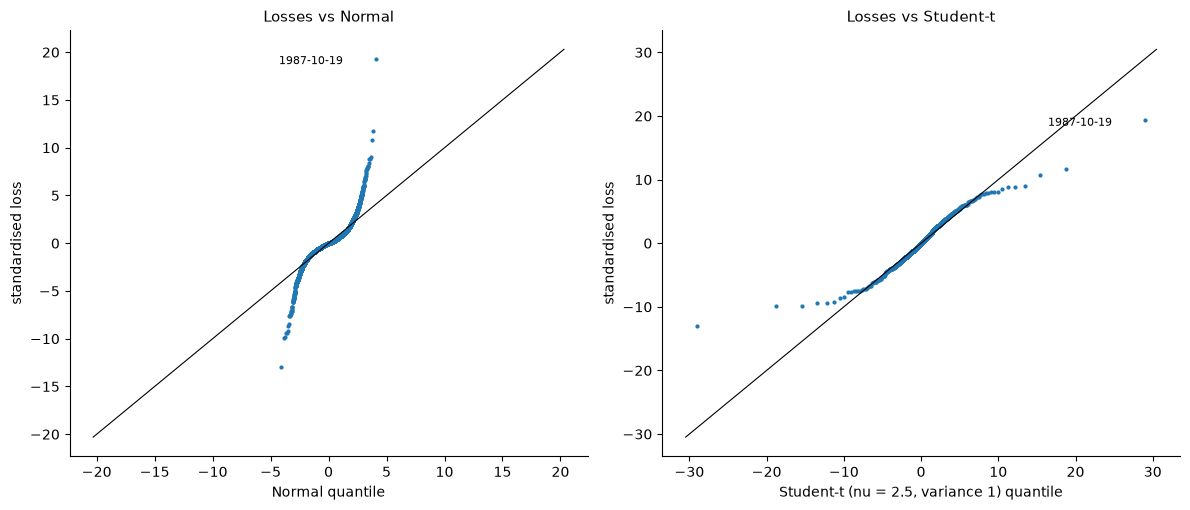

99.9% quantile of standardised losses: data 6.43, normal 3.09, t 6.19
Largest standardised loss 19.3 on 1987-10-19; largest gain 12.9 on 1933-03-15


In [ ]:
# 2.2 QQ plots of the losses against the normal and a Student-t fitted to all days
nu_all, loc_all, scale_all = stats.t.fit(x)                     # quick fit, for the plot only
print(f"Student-t fitted to all {len(x):,} days: nu = {nu_all:.2f}")

fig = plot_qq(x, nu_all)
fig.savefig(FIGURES / "qq_plots.png", dpi=150, bbox_inches="tight")
plt.show()

z = (x - x.mean()) / x.std()
p999 = 1 - 1 / 1000
t999 = stats.t.ppf(p999, nu_all) * np.sqrt((nu_all - 2) / nu_all)
print(f"99.9% quantile of standardised losses: data {z.quantile(p999):.2f}, normal {stats.norm.ppf(p999):.2f}, "
      f"t {t999:.2f}")
print(f"Largest standardised loss {z.max():.1f} on {z.idxmax().date()}; largest gain {(-z).max():.1f} on {(-z).idxmax().date()}")

**Findings – Section 2 (the tails).** Daily losses are strongly fat-tailed: excess kurtosis 18.7, the 99.9% quantile is **2.1 times** the normal one, and there are **57 days beyond 5 standard deviations where a normal predicts 0.007**. 19 Oct 1987 is a 19.3-sd day. The tail is fat in every era, fattest in 1987–2026 for the loss side (kurtosis 25, skew +1.1: crashes are larger than rallies). A Student-t fitted to all days needs ν = 2.5 — barely a finite variance — to follow the tail.

## 3. The Hill estimator

The simplest EVT tool: the tail index ξ from the k largest losses, and the VaR it implies. Its weak point — the choice of k — motivates Section 4.

### 3.1 The Hill estimator: hand check and simulated tails

| | |
|---|---|
| **1. What do I need to determine?** | Is `hill` correct, and how does its accuracy depend on k? |
| **2. What information and assumptions do I have?** | The theory-note example (expected ξ = 0.4234, se 0.1893); simulated Pareto (exact power law, ξ = 0.5) and Student-t(4) (power law only in the far tail, ξ = 0.25). |
| **3. Which method is appropriate?** | Equation 6 with a cumulative sum (all k at once); standard error ξ/√k (Equation 7). |
| **4. Why should the method work?** | For an exact Pareto every k is unbiased; for a t, a large k reaches into the body and biases ξ upwards — this is the bias–variance trade-off of k. |
| **5. How can I verify the answer?** | The toy example to 4 decimals; error/se within ±2 for the Pareto at every k. |

In [ ]:
# 3.1 Hill estimator: hand check on the theory-note example, then validation on simulated tails
toy = np.array([9, 7, 6, 5, 4.5, 4])
xi_toy, se_toy = hill(toy, 5)
print(f"Theory-note example: xi = {xi_toy:.4f} (expected 0.4234), se = {se_toy:.4f} (expected 0.1893)")

rng = np.random.default_rng(0)
n = len(x)                                                     # same size as our sample
pareto = rng.pareto(2.0, n) + 1                                # Pareto, alpha = 2 -> xi = 0.5
student = rng.standard_t(4, n)                                 # Student-t, nu = 4 -> xi = 0.25
ks = np.array([50, 100, 250, 500, 1000, 2500])

rows = {}
for name, data, true in [("Pareto (xi = 0.50)", pareto, 0.50), ("Student-t nu=4 (xi = 0.25)", student, 0.25)]:
    xi_k, se_k = hill(data, ks)
    for k, a, b in zip(ks, xi_k, se_k):
        rows[(name, k)] = {"xi": a, "se": b, "error": a - true, "error / se": (a - true) / b}
print(f"\nSimulated samples of {n:,} points:")
print(pd.DataFrame(rows).T.round(3).to_string())

Theory-note example: xi = 0.4234 (expected 0.4234), se = 0.1893 (expected 0.1893)

Simulated samples of 24,818 points:
                                    xi     se  error  error / se
Pareto (xi = 0.50)         50    0.437  0.062 -0.063      -1.026
                           100   0.503  0.050  0.003       0.054
                           250   0.504  0.032  0.004       0.140
                           500   0.495  0.022 -0.005      -0.239
                           1000  0.478  0.015 -0.022      -1.451
                           2500  0.489  0.010 -0.011      -1.097
Student-t nu=4 (xi = 0.25) 50    0.246  0.035 -0.004      -0.126
                           100   0.250  0.025  0.000       0.020
                           250   0.270  0.017  0.020       1.168
                           500   0.310  0.014  0.060       4.314
                           1000  0.335  0.011  0.085       8.009
                           2500  0.427  0.009  0.177      20.747


### 3.2 Hill plot of both tails

| | |
|---|---|
| **1. What do I need to determine?** | The tail index of S&P 500 losses and gains, and a sensible k. |
| **2. What information and assumptions do I have?** | Losses (right tail) and gains (−losses). |
| **3. Which method is appropriate?** | Plot ξ_k with its 95% band for k = 20…2,500 (log scale); table at selected k. |
| **4. Why should the method work?** | A plateau in the Hill plot (ξ stable over a range of k) is the region where bias is small and variance acceptable. |
| **5. How can I verify the answer?** | Both tails should give similar ξ if the distribution is roughly symmetric in its extremes. |

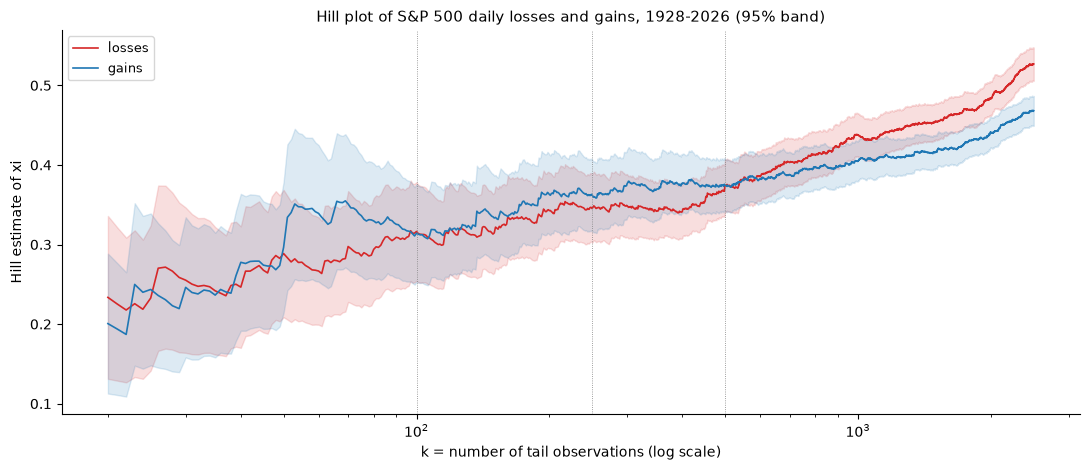

             share %  threshold %     xi     se  alpha = 1/xi  95% low  95% high
losses 50      0.201        6.005  0.289  0.041         3.465    0.209     0.369
       100     0.403        4.787  0.316  0.032         3.161    0.254     0.378
       150     0.604        4.227  0.315  0.026         3.179    0.264     0.365
       250     1.007        3.451  0.345  0.022         2.897    0.302     0.388
       500     2.015        2.632  0.374  0.017         2.671    0.342     0.407
       1000    4.029        1.871  0.437  0.014         2.287    0.410     0.464
       2500   10.073        1.116  0.527  0.011         1.898    0.506     0.548
gains  50      0.201        5.823  0.296  0.042         3.374    0.214     0.379
       100     0.403        4.544  0.314  0.031         3.183    0.253     0.376
       150     0.604        3.914  0.333  0.027         3.000    0.280     0.387
       250     1.007        3.175  0.362  0.023         2.764    0.317     0.407
       500     2.015        

In [ ]:
# 3.2 Hill plot of both tails, and the estimates at selected k
fig = plot_hill(x)
fig.savefig(FIGURES / "hill_plot.png", dpi=150, bbox_inches="tight")
plt.show()

ks = np.array([50, 100, 150, 250, 500, 1000, 2500])
rows = {}
for name, data in [("losses", x), ("gains", -x)]:
    xi_k, se_k = hill(data, ks)
    thr = np.sort(np.asarray(data))[::-1][ks]                        # threshold = (k+1)-th largest
    for k, a, b, u in zip(ks, xi_k, se_k, thr):
        rows[(name, k)] = {"share %": 100 * k / len(x), "threshold %": u, "xi": a, "se": b,
                           "alpha = 1/xi": 1 / a, "95% low": a - 1.96 * b, "95% high": a + 1.96 * b}
print(pd.DataFrame(rows).T.round(3).to_string())

### 3.3 Tail index by era

| | |
|---|---|
| **1. What do I need to determine?** | Has the tail become fatter or thinner over time? |
| **2. What information and assumptions do I have?** | The three eras of 2.1. |
| **3. Which method is appropriate?** | Hill at the same share of days (0.6%, 1%, 2%) in each era, so the comparison uses comparable tails. |
| **4. Why should the method work?** | Using a share instead of a fixed k avoids comparing a far tail with a near tail in eras of different length. |
| **5. How can I verify the answer?** | Scale invariance: multiplying the losses by 2 must not change ξ. |

In [ ]:
# 3.3 Tail index by era: Hill at the same share of days in each era, both tails
rows = {}
for era, (a, b) in {"full sample": (None, None), **ERAS}.items():
    sub = x.loc[a:b]
    for share in (0.006, 0.01, 0.02):
        k = int(round(share * len(sub)))
        for name, data in [("losses", sub), ("gains", -sub)]:
            xi_k, se_k = hill(data, k)
            rows[(era, name, f"{100 * share:.1f}%")] = {
                "k": k, "xi": xi_k, "alpha": 1 / xi_k, "95% low": xi_k - 1.96 * se_k, "95% high": xi_k + 1.96 * se_k}
tab = pd.DataFrame(rows).T
tab.index.names = ["era", "tail", "share"]
print(tab.unstack("tail").round(3).to_string())

print("\nScale invariance check: xi of losses x 2 equals xi of losses:",
      np.isclose(hill(2 * x, 150)[0], hill(x, 150)[0]))

                       k            xi         alpha        95% low        95% high       
tail               gains losses  gains losses  gains losses   gains losses    gains losses
era         share                                                                         
1928-1945   0.6%    27.0   27.0  0.233  0.275  4.297  3.640   0.145  0.171    0.320  0.378
            1.0%    45.0   45.0  0.341  0.263  2.936  3.801   0.241  0.186    0.440  0.340
            2.0%    90.0   90.0  0.378  0.310  2.649  3.224   0.300  0.246    0.456  0.374
1946-1986   0.6%    62.0   62.0  0.232  0.263  4.317  3.809   0.174  0.197    0.289  0.328
            1.0%   103.0  103.0  0.256  0.304  3.909  3.293   0.206  0.245    0.305  0.362
            2.0%   206.0  206.0  0.270  0.305  3.705  3.279   0.233  0.263    0.307  0.347
1987-2026   0.6%    60.0   60.0  0.312  0.344  3.209  2.906   0.233  0.257    0.391  0.431
            1.0%   100.0  100.0  0.347  0.369  2.879  2.711   0.279  0.297    0.415  0.441

### 3.4 Hill (Weissman) VaR and ES

| | |
|---|---|
| **1. What do I need to determine?** | VaR and ES at 99%, 99.5% and 99.9% from the Hill tail. |
| **2. What information and assumptions do I have?** | Hill ξ at k = 100, 150, 250; the threshold is the (k+1)-th largest loss. |
| **3. Which method is appropriate?** | Equations 8–9: $\text{VaR}_q = X_{(k+1)}\,(k/(n(1-q)))^{\xi}$, ES = VaR/(1 − ξ). |
| **4. Why should the method work?** | The power law extrapolates from the threshold to rarer levels with the estimated slope. |
| **5. How can I verify the answer?** | On simulated Pareto data the VaR must match $(1-q)^{-0.5}$; on the S&P 500 compare with the empirical quantile. |

In [ ]:
# 3.4 Hill (Weissman) VaR and ES: check on Pareto data, then the S&P 500 losses for k = 100, 150, 250
levels = np.array([0.99, 0.995, 0.999])

v_par, e_par = hill_var_es(pareto, 250, levels)                     # simulated Pareto from 3.1 (xi = 0.5)
print("Pareto check (true VaR = (1-q)^-0.5):")
print(pd.DataFrame({"Hill VaR": v_par, "true VaR": (1 - levels) ** -0.5}, index=levels).round(2).to_string())

rows = {}
for k in (100, 150, 250):
    v, e = hill_var_es(x, k, levels)
    for q, vv, ee in zip(levels, v, e):
        rows[(k, q)] = {"Hill VaR %": vv, "Hill ES %": ee}
emp = {q: np.quantile(x, q) for q in levels}
tab = pd.DataFrame(rows).T
tab.index.names = ["k", "q"]
tab["empirical VaR %"] = [emp[q] for q in tab.index.get_level_values("q")]
tab["normal VaR %"] = [x.mean() + x.std() * stats.norm.ppf(q) for q in tab.index.get_level_values("q")]
tab["USD loss on 10m (Hill VaR)"] = 1e7 * (1 - np.exp(-tab["Hill VaR %"] / 100))
print("\nS&P 500 daily losses, 1928-2026:")
print(tab.round(2).to_string(float_format=lambda v: f"{v:,.2f}"))

Pareto check (true VaR = (1-q)^-0.5):
       Hill VaR  true VaR
0.990      9.51     10.00
0.995     13.50     14.14
0.999     30.40     31.62

S&P 500 daily losses, 1928-2026:
           Hill VaR %  Hill ES %  empirical VaR %  normal VaR %  USD loss on 10m (Hill VaR)
k   q                                                                                      
100 0.990        3.59       5.25             3.45          2.73                  352,682.70
    0.995        4.47       6.54             4.49          3.03                  437,251.73
    0.999        7.44      10.88             7.60          3.64                  716,975.50
150 0.990        3.61       5.26             3.45          2.73                  354,360.33
    0.995        4.49       6.55             4.49          3.03                  438,784.30
    0.999        7.44      10.86             7.60          3.64                  717,436.88
250 0.990        3.46       5.28             3.45          2.73                  340,062

**Findings – Section 3 (Hill).** The estimator is exact on the hand example and unbiased on Pareto data, but on t(4) data it is **biased upwards once k exceeds about 1% of the sample** (error 4–21 se) — the bias–variance trade-off of k. On S&P 500 losses, ξ ≈ **0.29–0.35 for k = 50–250** (α ≈ 3), rising steadily with k (0.53 at k = 2,500): no clean plateau. Losses and gains have similar tails; the modern era has the fattest loss tail. Hill VaR at k = 150: **7.44% at 99.9%** against 7.60% historical and 3.64% normal.

## 4. Peaks over threshold: choosing the threshold and fitting the GPD

Above a high threshold u, the excess losses follow a Generalized Pareto Distribution (Pickands–Balkema–de Haan). The work is to choose u and to check the fit.

### 4.1 The mean excess function

| | |
|---|---|
| **1. What do I need to determine?** | Above which threshold do the excesses look like a GPD? |
| **2. What information and assumptions do I have?** | For a GPD the mean excess $e(u) = (\beta + \xi u)/(1-\xi)$ is a straight line in u, with slope ξ/(1 − ξ) (Equation 15). |
| **3. Which method is appropriate?** | `mean_excess` over a grid of u, with standard errors. |
| **4. Why should the method work?** | Linear e(u) above u means a GPD fits there; an upward slope means ξ > 0 (fat tail). |
| **5. How can I verify the answer?** | Exponential data (ξ = 0) give a flat e(u) = 1; Pareto α = 2 gives e(u) = u. |

In [ ]:
# 4.1 Mean excess function: checks on exponential and Pareto data, then the S&P 500 losses
rng = np.random.default_rng(1)
expo = rng.exponential(1.0, 200_000)                           # xi = 0: e(u) = 1 everywhere
par2 = rng.pareto(2.0, 200_000) + 1                            # xi = 0.5: e(u) = u
print("Exponential (expected 1.00 at every u):")
print(mean_excess(expo, [0.5, 1, 2, 4]).round(3).to_string())
print("\nPareto alpha = 2 (expected e(u) = u):")
print(mean_excess(par2, [2, 4, 8, 16]).round(3).to_string())

me = mean_excess(x, np.arange(0.5, 8.01, 0.5))
me["share above %"] = 100 * me["n above"] / len(x)
print("\nS&P 500 losses:")
print(me.round(3).to_string())

# slope of e(u) between thresholds -> implied xi = slope / (1 + slope)
for a, b in [(1.0, 2.0), (2.0, 3.0), (3.0, 4.5), (4.5, 6.5)]:
    slope = (me.loc[b, "mean excess"] - me.loc[a, "mean excess"]) / (b - a)
    print(f"u {a:.1f} -> {b:.1f}: slope {slope:.3f}, implied xi {slope / (1 + slope):.3f}")

Exponential (expected 1.00 at every u):
     n above  mean excess     se
u                               
0.5   121122        0.995  0.003
1.0    73447        0.993  0.004
2.0    26753        0.993  0.006
4.0     3579        0.975  0.016

Pareto alpha = 2 (expected e(u) = u):
      n above  mean excess     se
u                                
2.0     49953        1.960  0.023
4.0     12351        3.900  0.084
8.0      3057        7.684  0.295
16.0      741       15.437  1.011

S&P 500 losses:
     n above  mean excess     se  share above %
u                                              
0.5     5823        0.845  0.014         23.463
1.0     2929        0.964  0.024         11.802
1.5     1565        1.111  0.037          6.306
2.0      886        1.297  0.055          3.570
2.5      563        1.412  0.075          2.269
3.0      378        1.487  0.099          1.523
3.5      241        1.710  0.135          0.971
4.0      168        1.856  0.171          0.677
4.5      124        1.

### 4.2 Mean excess plot with a weighted line

| | |
|---|---|
| **1. What do I need to determine?** | Where is e(u) linear, and which ξ does its slope imply? |
| **2. What information and assumptions do I have?** | e(u) on a fine grid; high thresholds have few points and large standard errors. |
| **3. Which method is appropriate?** | Weighted least squares (weights 1/se) over several ranges; ξ = slope/(1 + slope). |
| **4. Why should the method work?** | Weighting stops the noisy right end of the plot from driving the slope. |
| **5. How can I verify the answer?** | The implied ξ should be stable when the start of the range moves. |

        slope  implied xi  points
1.5-6%  0.258       0.205    90.0
2-6%    0.248       0.199    80.0
2.5-6%  0.253       0.202    70.0
3-6%    0.219       0.179    60.0


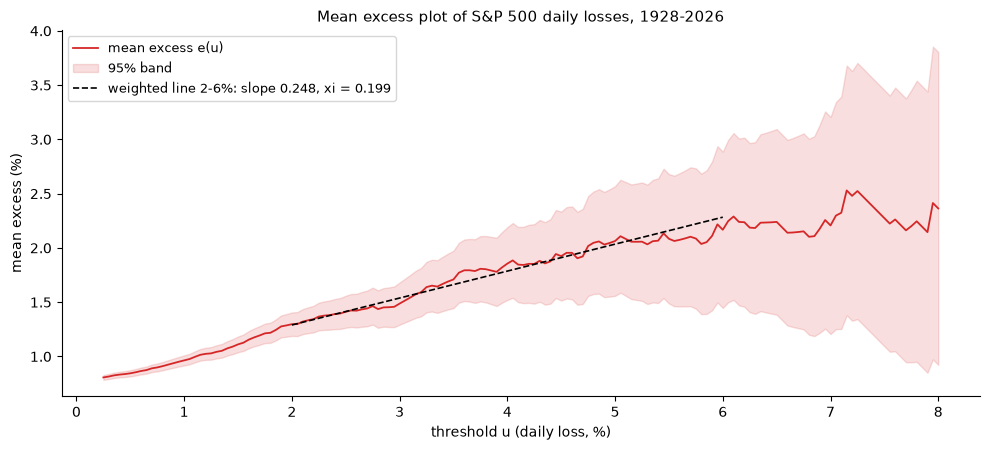

In [ ]:
# 4.2 Mean excess plot with a weighted straight line over the candidate linear range
me_fine = mean_excess(x, np.arange(0.25, 8.01, 0.05))
rows = {}
for a, b in [(1.5, 6.0), (2.0, 6.0), (2.5, 6.0), (3.0, 6.0)]:
    seg = me_fine.loc[a:b]
    slope, icpt = np.polyfit(seg.index.values, seg["mean excess"].values, 1, w=1 / seg["se"].values)
    rows[f"{a:g}-{b:g}%"] = {"slope": slope, "implied xi": slope / (1 + slope), "points": len(seg)}
fits = pd.DataFrame(rows).T
print(fits.round(3).to_string())

s, i = np.polyfit(me_fine.loc[2.0:6.0].index.values, me_fine.loc[2.0:6.0, "mean excess"].values, 1,
                  w=1 / me_fine.loc[2.0:6.0, "se"].values)
fig = plot_mean_excess(me_fine, fit=(2.0, 6.0, s, i), u_max=8.0)
fig.savefig(FIGURES / "mean_excess.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 GPD maximum likelihood

| | |
|---|---|
| **1. What do I need to determine?** | ξ and β of the excesses, with standard errors, at several thresholds. |
| **2. What information and assumptions do I have?** | Excesses $y = x - u$ for $x > u$; log-likelihood Equation 11. |
| **3. Which method is appropriate?** | Nelder–Mead from method-of-moments starting values; standard errors from the inverse numerical Hessian. |
| **4. Why should the method work?** | Maximum likelihood is efficient for ξ > −0.5; a derivative-free optimiser handles the boundary of the valid region safely. |
| **5. How can I verify the answer?** | Simulated GPD: same estimates as `scipy.stats.genpareto.fit`, se close to the theoretical $(1+\xi)/\sqrt{n}$. |

In [ ]:
# 4.3 GPD maximum likelihood: checks on simulated GPD data, then the S&P 500 excesses at several thresholds
rows = {}
for n_sim in (500, 20_000):
    y_sim = stats.genpareto.rvs(c=0.25, scale=0.7, size=n_sim, random_state=0)
    ours = fit_gpd(y_sim)
    c_sp, _, b_sp = stats.genpareto.fit(y_sim, floc=0)
    rows[n_sim] = {"xi (ours)": ours["xi"], "xi (scipy)": c_sp, "beta (ours)": ours["beta"], "beta (scipy)": b_sp,
                   "se xi": ours["se_xi"], "theory se xi": 1.25 / np.sqrt(n_sim), "converged": ours["converged"]}
print("Simulated GPD, true xi = 0.25, beta = 0.70:")
print(pd.DataFrame(rows).T.round(4).to_string())

rows = {}
for u in (1.5, 2.0, 2.5, 3.0, 3.5):
    y = x[x > u].values - u
    f = fit_gpd(y)
    rows[u] = {"N_u": f["n"], "share %": 100 * f["n"] / len(x), "xi": f["xi"], "se xi": f["se_xi"],
               "95% low": f["xi"] - 1.96 * f["se_xi"], "95% high": f["xi"] + 1.96 * f["se_xi"],
               "beta": f["beta"], "se beta": f["se_beta"], "converged": f["converged"]}
gpd_u = pd.DataFrame(rows).T
gpd_u.index.name = "threshold u %"
print("\nS&P 500 loss excesses:")
print(gpd_u.round(3).to_string())

Simulated GPD, true xi = 0.25, beta = 0.70:
      xi (ours) xi (scipy) beta (ours) beta (scipy)     se xi theory se xi converged
500    0.285351   0.285336    0.682803      0.68279  0.060276     0.055902      True
20000  0.261725   0.261727     0.68461     0.684598  0.009001     0.008839      True

S&P 500 loss excesses:
                N_u   share %        xi     se xi   95% low  95% high      beta   se beta converged
threshold u %                                                                                      
1.5            1565  6.305907  0.244774  0.032769  0.180547  0.309002  0.843764  0.034527      True
2.0             886   3.56999  0.191025  0.039953  0.112717  0.269333  1.049946  0.054392      True
2.5             563  2.268515  0.194101  0.050381  0.095355  0.292847  1.138645  0.074209      True
3.0             378  1.523088  0.257178   0.07077  0.118468  0.395887  1.116116  0.096523      True
3.5             241  0.971069  0.172349  0.077963  0.019541  0.325157  1.4162

### 4.4 Parameter stability over thresholds

| | |
|---|---|
| **1. What do I need to determine?** | Over which range of u are ξ and the modified scale β* = β − ξu constant? |
| **2. What information and assumptions do I have?** | If a GPD holds above u₀, it holds above every u > u₀ with the same ξ and the same β*. |
| **3. Which method is appropriate?** | `threshold_stability`: GPD fits for u = 1.0 … 4.5%, with delta-method se for β*. |
| **4. Why should the method work?** | Constant parameters over thresholds are the formal version of 'the line in the mean excess plot is straight'. |
| **5. How can I verify the answer?** | Same ξ as 4.3 at the shared thresholds; hand check of β* at u = 2%; every fit converged. |

In [ ]:
# 4.4 Parameter stability: xi and the modified scale beta* = beta - xi u over a grid of thresholds

stab = threshold_stability(x, np.round(np.arange(1.0, 4.51, 0.1), 1))

same = np.allclose(stab.loc[[1.5, 2.0, 2.5, 3.0, 3.5], "xi"].values, gpd_u["xi"].astype(float).values, atol=1e-6)
print(f"Same xi as Step 4.3 at u = 1.5, 2.0, 2.5, 3.0, 3.5: {same}")
r = stab.loc[2.0]
print(f"Hand check at u = 2.0: beta - xi u = {r['beta']:.4f} - {r['xi']:.4f} x 2 = {r['beta'] - 2 * r['xi']:.4f} "
      f"(table: {r['beta_star']:.4f})")
print(f"All fits converged: {stab['converged'].all()}\n")
print(stab.iloc[::2].round(3).to_string())

Same xi as Step 4.3 at u = 1.5, 2.0, 2.5, 3.0, 3.5: True
Hand check at u = 2.0: beta - xi u = 1.0499 - 0.1910 x 2 = 0.6679 (table: 0.6679)
All fits converged: True

      N_u     xi  se_xi   beta  beta_star  se_beta_star  converged
u                                                                 
1.0  2929  0.234  0.023  0.740      0.506         0.040       True
1.2  2254  0.232  0.026  0.788      0.510         0.052       True
1.4  1774  0.251  0.031  0.810      0.459         0.068       True
1.6  1378  0.230  0.034  0.893      0.525         0.085       True
1.8  1105  0.222  0.038  0.951      0.551         0.104       True
2.0   886  0.191  0.040  1.050      0.668         0.122       True
2.2   735  0.192  0.044  1.086      0.663         0.145       True
2.4   614  0.191  0.048  1.125      0.666         0.169       True
2.6   521  0.207  0.054  1.130      0.593         0.199       True
2.8   449  0.242  0.062  1.096      0.418         0.238       True
3.0   378  0.257  0.071  1.116 

### 4.5 Stability chart and the chosen threshold

| | |
|---|---|
| **1. What do I need to determine?** | One threshold for the rest of the project. |
| **2. What information and assumptions do I have?** | Stability table (4.4), mean excess (4.2), Hill at the same number of exceedances. |
| **3. Which method is appropriate?** | Choose the lowest u where ξ and β* are stable: **u = 2%** (886 exceedances, 3.6% of days). |
| **4. Why should the method work?** | The lowest stable threshold uses the most data (low variance) without bias. |
| **5. How can I verify the answer?** | ξ stays inside its 95% band from 1.5% to 3.4%; compare with Hill at the same k. |

Hill at k = 887 (u = 2%): 0.423  (between Hill k = 500: 0.372 and k = 1000: 0.438)
GPD at u = 2%: xi = 0.191 +/- 0.078


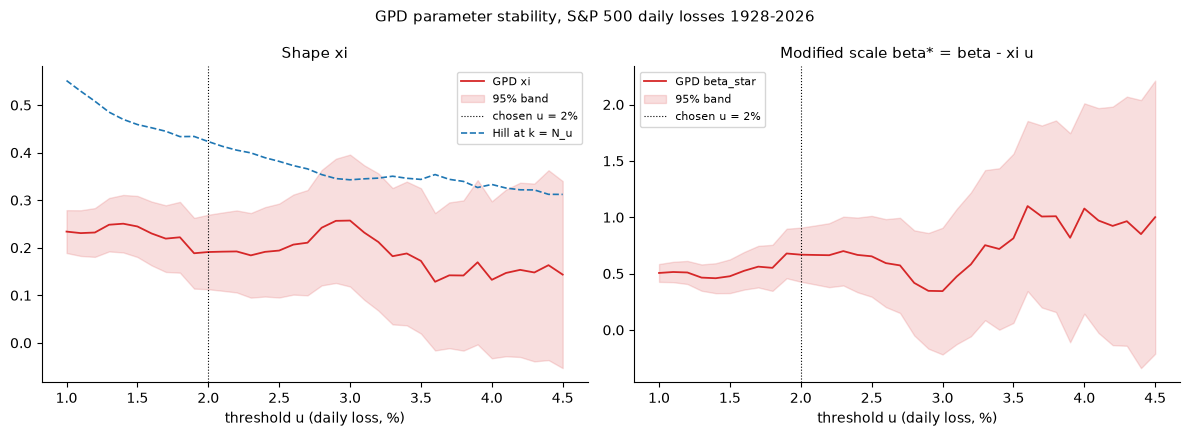

In [ ]:
# 4.5 Stability chart (GPD xi and beta*, Hill at the same k), and the chosen threshold
U_GPD = 2.0                                                    # chosen threshold, % daily loss
hill_same_k = np.array([hill(x, int(n))[0] for n in stab["N_u"]])
print(f"Hill at k = 887 (u = 2%): {hill_same_k[stab.index.get_loc(2.0)]:.3f}  "
      f"(between Hill k = 500: 0.372 and k = 1000: 0.438)")
print(f"GPD at u = 2%: xi = {stab.loc[2.0, 'xi']:.3f} +/- {1.96 * stab.loc[2.0, 'se_xi']:.3f}")

fig = plot_stability(stab, hill_xi=hill_same_k, u_chosen=U_GPD)
fig.savefig(FIGURES / "gpd_stability.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.6 Goodness of fit at u = 2%

| | |
|---|---|
| **1. What do I need to determine?** | Does the GPD at u = 2% describe the tail, including the largest losses? |
| **2. What information and assumptions do I have?** | ξ = 0.191, β = 1.050, N_u = 886 of 24,818. |
| **3. Which method is appropriate?** | QQ plot of the excesses; tail plot P(loss > x) on log–log axes against the data and the normal; tail probabilities (Equation 12). |
| **4. Why should the method work?** | The tail plot shows directly whether the model's exceedance probabilities match the observed frequencies far out. |
| **5. How can I verify the answer?** | Number of observed days beyond 3, 5, 7.6, 10, 15% against the GPD and normal predictions. |

GPD at u = 2.0%: xi = 0.1910 (se 0.0400), beta = 1.0499 (se 0.0544), N_u = 886 of 24,818


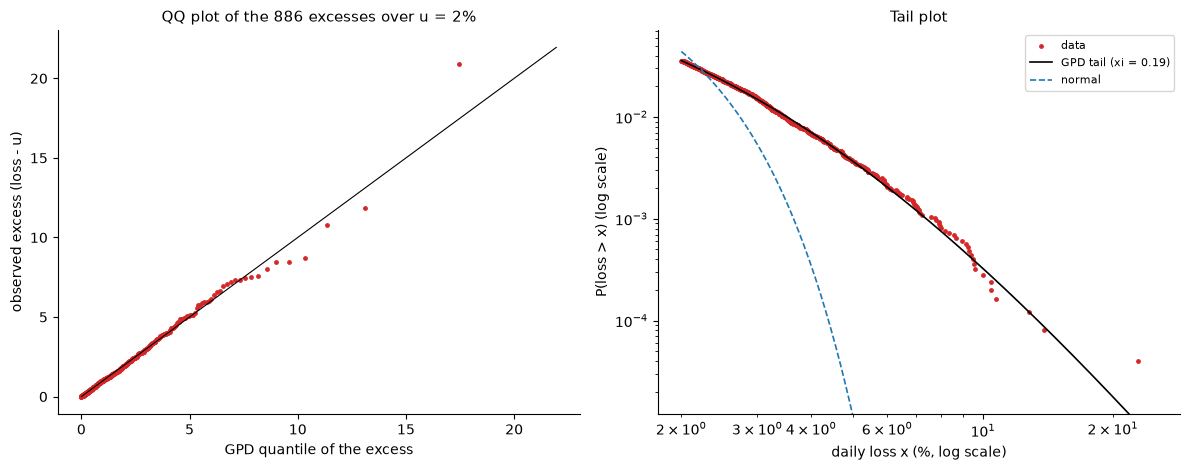


Probability of a daily loss of at least x % (and how often, in years of 252 days):
      days in data   P data    P GPD  P normal  once every (years) GPD  once every (years) normal
3.0            378   0.0152   0.0149   0.00537                   0.267                      0.739
5.0             90  0.00363  0.00365  1.13e-05                    1.09                        352
7.6             25  0.00101 0.000903  6.35e-11                     4.4                   6.25e+07
10.0             6 0.000242 0.000324   1.4e-17                    12.3                   2.84e+14
15.0             1 4.03e-05 6.22e-05  4.22e-37                    63.8                   9.41e+33
22.9             0        0 9.67e-06  1.36e-83                     411                   2.93e+80


In [ ]:
# 4.6 Goodness of fit of the GPD at u = 2%: QQ plot of the excesses, tail plot, and tail probabilities
g = fit_gpd(x[x > U_GPD].values - U_GPD)
XI, BETA, N_U, N = g["xi"], g["beta"], g["n"], len(x)
print(f"GPD at u = {U_GPD}%: xi = {XI:.4f} (se {g['se_xi']:.4f}), beta = {BETA:.4f} (se {g['se_beta']:.4f}), "
      f"N_u = {N_U} of {N:,}")

fig = plot_gpd_fit(x, U_GPD, XI, BETA)
fig.savefig(FIGURES / "gpd_fit.png", dpi=150, bbox_inches="tight")
plt.show()

rows = {}
for loss in (3.0, 5.0, 7.6, 10.0, 15.0, 22.9):
    emp = (x >= loss).sum() / N
    gpd = (N_U / N) * (1 + XI * (loss - U_GPD) / BETA) ** (-1 / XI)
    nrm = stats.norm.sf(loss, x.mean(), x.std())
    rows[loss] = {"days in data": int((x >= loss).sum()), "P data": emp, "P GPD": gpd, "P normal": nrm,
                  "once every (years) GPD": 1 / (252 * gpd), "once every (years) normal": 1 / (252 * nrm)}
print("\nProbability of a daily loss of at least x % (and how often, in years of 252 days):")
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f"{v:.3g}"))

**Findings – Section 4 (GPD).** Our maximum likelihood equals scipy's to 4 decimals. The mean excess plot is linear from about 2% (weighted slope 0.25, ξ ≈ 0.20); ξ and β* are stable from 1.5% to 3.4%. **Chosen threshold u = 2%**: 886 exceedances (3.6% of days), **ξ = 0.191 (se 0.040), β = 1.050** — α ≈ 5, a thinner tail than Hill suggests, because Hill at the same k (0.42) suffers from the bias seen in 3.1. The fit is good up to the largest losses: the GPD predicts a 10% loss once every 12 years (6 days observed in 98 years), the normal once every 3 × 10¹⁴ years; 19 Oct 1987 is a **once-in-400-years** event for the GPD.

## 5. Extreme VaR and ES

The GPD tail turned into VaR and ES, compared with the normal, the Student-t, historical simulation and Hill — inside the data (99–99.9%) and beyond it (once in 10 and 100 years).

### 5.1 GPD VaR and ES

| | |
|---|---|
| **1. What do I need to determine?** | VaR and ES at 99%, 99.5%, 99.9% from the GPD tail, and their sensitivity to u. |
| **2. What information and assumptions do I have?** | Equations 13–14; the fitted tail at u = 1.5, 2, 2.5, 3%. |
| **3. Which method is appropriate?** | `gpd_var_es`, checked on 1,000,000 simulated points with an exact GPD tail, and in the exponential limit ξ = 0. |
| **4. Why should the method work?** | The formulas are exact for a GPD tail; the only error left is estimation error. |
| **5. How can I verify the answer?** | Formula vs simulation; ξ = 0 gives 2 + ln 100; VaR stable across thresholds. |

In [ ]:
# 5.1 GPD VaR and ES: check on a simulated sample with an exact GPD tail, then the S&P 500 for four thresholds
levels = np.array([0.99, 0.995, 0.999])

# (a) Simulation: below u = 2 uniform, above u = 2 exact GPD(0.19, 1.05) with probability 887 / 24,819
rng = np.random.default_rng(2)
m = 1_000_000
above = rng.random(m) < N_U / N
sim = np.where(above, U_GPD + stats.genpareto.rvs(c=XI, scale=BETA, size=m, random_state=3),
               rng.uniform(-2, U_GPD, m))
v_f, e_f = gpd_var_es(U_GPD, XI, BETA, m, above.sum(), levels)
v_e = np.quantile(sim, levels)
e_e = [sim[sim > v].mean() for v in v_e]
print("Simulated exact GPD tail (1,000,000 points):")
print(pd.DataFrame({"VaR formula": v_f, "VaR empirical": v_e, "ES formula": e_f, "ES empirical": e_e},
                   index=levels).round(3).to_string())
print(f"Exponential limit (xi = 0): VaR {gpd_var_es(2.0, 0.0, 1.0, 1000, 100, 0.999)[0]:.4f} "
      f"= 2 + ln(100) = {2 + np.log(100):.4f}")

# (b) S&P 500: GPD VaR / ES for thresholds 1.5 - 3.0 %, with empirical and normal values
rows = {}
for u in (1.5, 2.0, 2.5, 3.0):
    f = fit_gpd(x[x > u].values - u)
    v, e = gpd_var_es(u, f["xi"], f["beta"], N, f["n"], levels)
    for q, vv, ee in zip(levels, v, e):
        rows[(u, q)] = {"xi": f["xi"], "GPD VaR %": vv, "GPD ES %": ee}
gpd_tab = pd.DataFrame(rows).T
gpd_tab.index.names = ["u %", "q"]
qs = gpd_tab.index.get_level_values("q")
gpd_tab["empirical VaR %"] = [np.quantile(x, q) for q in qs]
gpd_tab["empirical ES %"] = [x[x > np.quantile(x, q)].mean() for q in qs]
print("\nS&P 500 daily losses, 1928-2026:")
print(gpd_tab.round(3).to_string())

Simulated exact GPD tail (1,000,000 points):
       VaR formula  VaR empirical  ES formula  ES empirical
0.990        3.509          3.536       5.163         5.222
0.995        4.500          4.565       6.389         6.470
0.999        7.379          7.528       9.947         9.993
Exponential limit (xi = 0): VaR 6.6052 = 2 + ln(100) = 6.6052

S&P 500 daily losses, 1928-2026:
              xi  GPD VaR %  GPD ES %  empirical VaR %  empirical ES %
u % q                                                                 
1.5 0.990  0.245      3.463     5.217            3.455           5.154
    0.995  0.245      4.463     6.541            4.495           6.409
    0.999  0.245      7.559    10.640            7.603           9.862
2.0 0.990  0.191      3.513     5.168            3.455           5.154
    0.995  0.191      4.505     6.394            4.495           6.409
    0.999  0.191      7.385     9.954            7.603           9.862
2.5 0.990  0.194      3.511     5.167            3.

### 5.2 The Student-t benchmark: our own maximum likelihood

| | |
|---|---|
| **1. What do I need to determine?** | A Student-t fitted to the losses, as a fat-tailed benchmark. |
| **2. What information and assumptions do I have?** | Location μ, scale s, degrees of freedom ν; t log-likelihood. |
| **3. Which method is appropriate?** | `fit_t`: L-BFGS-B with bounds ν ∈ [2.05, 200], robust starting values (median, MAD). |
| **4. Why should the method work?** | The t has a power-law tail with ξ = 1/ν, so it is the natural parametric competitor to EVT. |
| **5. How can I verify the answer?** | Same estimates as `scipy.stats.t.fit`, on simulated t(4) data and on the S&P 500. |

In [ ]:
# 5.2 Student-t maximum likelihood: check on simulated t(4) data and against scipy, then the S&P 500 losses
rng = np.random.default_rng(4)
t_sim = 0.1 + 0.8 * rng.standard_t(4, 25_000)                        # mu 0.1, scale 0.8, nu 4
rows = {}
for name, data in [("simulated t(4)", t_sim), ("S&P 500 losses", x.values)]:
    ours = fit_t(data)
    nu_sp, mu_sp, s_sp = stats.t.fit(data)
    rows[name] = {"mu": ours["mu"], "mu scipy": mu_sp, "scale": ours["scale"], "scale scipy": s_sp,
                  "nu": ours["nu"], "nu scipy": nu_sp, "sd (t)": ours["sd"], "sd (sample)": np.std(data, ddof=1),
                  "converged": ours["converged"]}
print(pd.DataFrame(rows).T.round(4).to_string())

T_FIT = fit_t(x.values)
print(f"\nS&P 500: nu = {T_FIT['nu']:.2f} -> tail index of the t: xi = 1/nu = {1 / T_FIT['nu']:.3f} "
      f"(GPD: {XI:.3f}; Hill k = 150: 0.315)")

                      mu  mu scipy     scale scale scipy        nu  nu scipy    sd (t) sd (sample) converged
simulated t(4)  0.099413  0.099416  0.809303    0.809304  4.024012  4.023983  1.141128    1.133264      True
S&P 500 losses -0.052993 -0.052997  0.645104    0.645101  2.535098  2.535105   1.40414     1.18563      True

S&P 500: nu = 2.54 -> tail index of the t: xi = 1/nu = 0.394 (GPD: 0.191; Hill k = 150: 0.315)


### 5.3 VaR and ES of the benchmarks

| | |
|---|---|
| **1. What do I need to determine?** | Are the normal, t and historical VaR/ES formulas correct? |
| **2. What information and assumptions do I have?** | Equations 17–19. |
| **3. Which method is appropriate?** | Compare each formula with 2,000,000 simulated draws. |
| **4. Why should the method work?** | A formula error would bias every comparison in 5.4. |
| **5. How can I verify the answer?** | Formula and simulation agree to the second decimal. |

In [ ]:
# 5.3 Benchmark VaR / ES formulas: check each one on 2,000,000 simulated draws
levels = np.array([0.99, 0.995, 0.999])
rng = np.random.default_rng(5)
m = 2_000_000

checks = {}
z_n = 0.05 + 1.2 * rng.standard_normal(m)                                  # normal, mu 0.05, sd 1.2
v_f, e_f = var_es_normal(0.05, 1.2, levels)
v_e, e_e = var_es_hist(z_n, levels)
checks["normal"] = (v_f, v_e, e_f, e_e)

nu = 4.0
z_t = 0.05 + 0.8 * rng.standard_t(nu, m)                                   # t, mu 0.05, scale 0.8, nu 4
v_f, e_f = var_es_t(0.05, 0.8, nu, levels)
v_e, e_e = var_es_hist(z_t, levels)
checks["t(4)"] = (v_f, v_e, e_f, e_e)

rows = {}
for name, (vf, ve, ef, ee) in checks.items():
    for q, a, b, c, d in zip(levels, vf, ve, ef, ee):
        rows[(name, q)] = {"VaR formula": a, "VaR simulated": b, "ES formula": c, "ES simulated": d}
print(pd.DataFrame(rows).T.round(3).to_string())

v_h, e_h = var_es_hist(x, 0.999)
print(f"\nHistorical on the S&P 500 at 99.9%: VaR {v_h[0]:.3f} (np.quantile {np.quantile(x, 0.999):.3f}), "
      f"ES {e_h[0]:.3f} (by hand {x[x > np.quantile(x, 0.999)].mean():.3f})")

              VaR formula  VaR simulated  ES formula  ES simulated
normal 0.990        2.842          2.841       3.248         3.245
       0.995        3.141          3.139       3.520         3.514
       0.999        3.758          3.752       4.091         4.089
t(4)   0.990        3.048          3.056       4.226         4.251
       0.995        3.733          3.760       5.110         5.143
       0.999        5.789          5.805       7.799         7.819

Historical on the S&P 500 at 99.9%: VaR 7.603 (np.quantile 7.603), ES 9.862 (by hand 9.862)


### 5.4 Six models side by side, and VaR by return period

| | |
|---|---|
| **1. What do I need to determine?** | How different are the models inside the data (99–99.9%) and beyond it (10 and 100 years)? |
| **2. What information and assumptions do I have?** | Normal, t (MLE), t scaled to the sample sd, historical, Hill (k = 150), GPD (u = 2%). |
| **3. Which method is appropriate?** | VaR/ES at three levels relative to historical; the 'once in N years' loss with q = 1 − 1/(252N) (Equation 16); return-level chart. |
| **4. Why should the method work?** | Inside the data, historical simulation is the reference; beyond it, only a tail model can extrapolate. |
| **5. How can I verify the answer?** | The empirical quantiles of the 100 largest losses on the chart. |

                      VaR %   ES %  VaR vs hist %  ES vs hist %
q     model                                                    
0.990 normal           2.73   3.14         -20.87        -39.17
0.995 normal           3.03   3.40         -32.60        -46.89
0.999 normal           3.64   3.97         -52.13        -59.77
0.990 t (MLE)          3.35   5.68          -2.96         10.22
0.995 t (MLE)          4.49   7.53          -0.14         17.50
0.999 t (MLE)          8.64  14.34          13.60         45.43
0.990 t (sample sd)    2.85   4.82         -17.48         -6.54
0.995 t (sample sd)    3.81   6.38         -15.23         -0.47
0.999 t (sample sd)    7.31  12.13          -3.81         23.00
0.990 historical       3.45   5.15           0.00          0.00
0.995 historical       4.49   6.41           0.00          0.00
0.999 historical       7.60   9.86           0.00          0.00
0.990 Hill (k = 150)   3.61   5.26           4.44          2.13
0.995 Hill (k = 150)   4.49   6.55      

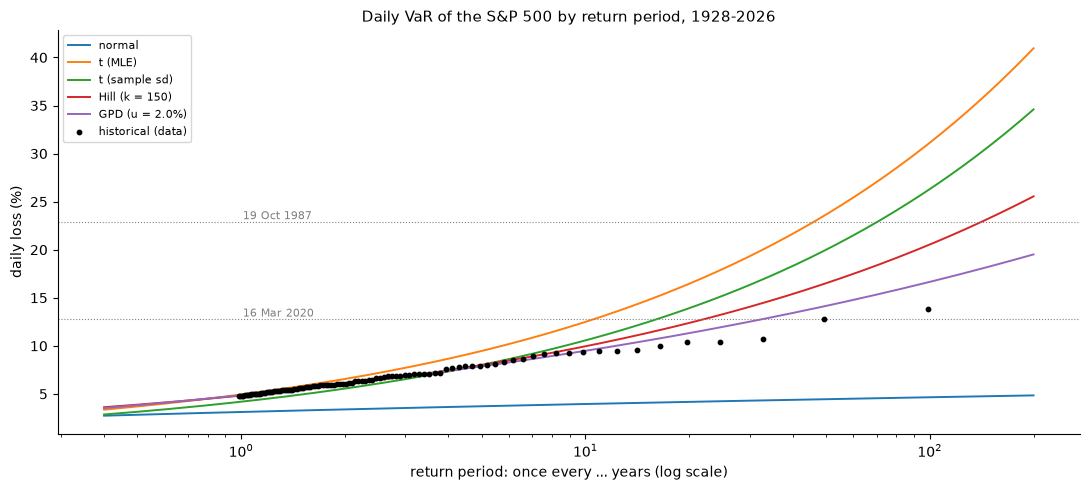

In [ ]:
# 5.4 Six models side by side at 99 / 99.5 / 99.9%, and the daily VaR by return period (beyond the data)
K_HILL = 150
mu, sd = x.mean(), x.std()
nu_t, s_t, mu_t = T_FIT["nu"], T_FIT["scale"], T_FIT["mu"]

def all_models(q):
    """VaR and ES of the six models at level(s) q."""
    return {"normal": var_es_normal(mu, sd, q),
            "t (MLE)": var_es_t(mu_t, s_t, nu_t, q),
            "t (sample sd)": var_es_t(mu, sd * np.sqrt((nu_t - 2) / nu_t), nu_t, q),
            "historical": var_es_hist(x, q),
            f"Hill (k = {K_HILL})": hill_var_es(x, K_HILL, q),
            f"GPD (u = {U_GPD}%)": gpd_var_es(U_GPD, XI, BETA, N, N_U, q)}

# (a) table at the three levels, error vs historical
levels = np.array([0.99, 0.995, 0.999])
res = all_models(levels)
rows = {}
for model, (v, e) in res.items():
    for i, q in enumerate(levels):
        rows[(q, model)] = {"VaR %": v[i], "ES %": e[i],
                            "VaR vs hist %": 100 * (v[i] / res["historical"][0][i] - 1),
                            "ES vs hist %": 100 * (e[i] / res["historical"][1][i] - 1)}
comp = pd.DataFrame(rows).T
comp.index.names = ["q", "model"]
print(comp.round(2).to_string())

# (b) return levels: once in 10, 50, 100 years
print("\nDaily loss expected once every N years (VaR at q = 1 - 1/(252 N)), %:")
ret = {}
for years in (10, 50, 100):
    q = 1 - 1 / (252 * years)
    ret[f"{years} years"] = {m: float(np.atleast_1d(v)[0]) for m, (v, e) in all_models(q).items() if m != "historical"}
print(pd.DataFrame(ret).round(2).to_string())

# (c) chart: VaR by return period, 0.4 to 200 years
years_grid = np.logspace(np.log10(0.4), np.log10(200), 200)
q_grid = 1 - 1 / (252 * years_grid)
curves = {m: (years_grid, np.asarray(v)) for m, (v, e) in all_models(q_grid).items() if m != "historical"}
emp_q = 1 - np.arange(1, 101) / N                                  # the 100 largest losses
emp_years = 1 / (252 * (1 - emp_q))
fig = plot_return_levels(curves, emp_years, np.quantile(x, emp_q),
                         events={"19 Oct 1987": x.max(), "16 Mar 2020": x.loc["2020-03-16"]})
fig.savefig(FIGURES / "return_levels.png", dpi=150, bbox_inches="tight")
plt.show()

**Findings – Section 5 (extreme VaR and ES).** GPD VaR/ES is stable across thresholds (99.9% VaR 7.38–7.56%) and within 3% of historical inside the data: **VaR 99.9% = 7.38%, ES 99.9% = 9.95%**. The normal is **52% too low** for VaR and 60% too low for ES at 99.9%; the t fitted by MLE is 14% too high for VaR and **45% too high for ES** (ν = 2.5 overstates the far tail). Beyond the data the models diverge: the 100-year daily loss is **16.7% (GPD)**, 20.6% (Hill), 31.1% (t) and 4.7% (normal). EVT is the only approach that both fits the data and extrapolates with a tail estimated from the tail.

## 6. How sure are we? Confidence intervals

An extreme quantile estimated from 886 exceedances is uncertain. Three ways to measure that uncertainty, and a simulation that checks which one is honest.

### 6.1 Delta-method confidence intervals

| | |
|---|---|
| **1. What do I need to determine?** | 95% intervals for the GPD VaR and ES, up to the 100-year loss. |
| **2. What information and assumptions do I have?** | Covariance of (ξ, β) from 4.3; N_u/n treated as known. |
| **3. Which method is appropriate?** | Equation 20: se = $\sqrt{\nabla^T \Sigma \nabla}$ with a numerical gradient. |
| **4. Why should the method work?** | First-order approximation, fast and standard; symmetric by construction. |
| **5. How can I verify the answer?** | Numerical gradient equal to the analytic gradient of Equation 13. |

In [ ]:
# 6.1 Delta-method 95% intervals for the GPD VaR and ES (u = 2%), including the 10- and 100-year levels
G_FIT = fit_gpd(x[x > U_GPD].values - U_GPD)

# check: numerical gradient = analytic gradient of VaR at 99.9%
r = (N / N_U) * 0.001
d_beta = (r ** -XI - 1) / XI
d_xi = -BETA / XI ** 2 * (r ** -XI - 1) - BETA / XI * r ** -XI * np.log(r)
se_analytic = np.sqrt(np.array([d_xi, d_beta]) @ G_FIT["cov"] @ np.array([d_xi, d_beta]))
print(f"VaR 99.9% se: delta method {gpd_var_ci(U_GPD, G_FIT, N, 0.999).loc[0.999, 'se']:.5f} "
      f"vs analytic gradient {se_analytic:.5f}")

q_list = [0.99, 0.995, 0.999, 1 - 1 / (252 * 10), 1 - 1 / (252 * 100)]
names = ["99%", "99.5%", "99.9%", "10 years", "100 years"]
ci = {}
for measure in ("var", "es"):
    t = gpd_var_ci(U_GPD, G_FIT, N, q_list, measure=measure)
    t.index = names
    t["width % of estimate"] = 100 * (t["high"] - t["low"]) / t["estimate"]
    ci[measure.upper()] = t
print(pd.concat(ci, axis=1).round(2).to_string())

VaR 99.9% se: delta method 0.32630 vs analytic gradient 0.32630
               VAR                                               ES                                        
          estimate    se    low   high width % of estimate estimate    se    low   high width % of estimate
99%           3.51  0.06   3.39   3.63                6.77     5.17  0.16   4.85   5.48               12.13
99.5%         4.50  0.10   4.31   4.70                8.79     6.39  0.26   5.88   6.91               16.18
99.9%         7.38  0.33   6.75   8.02               17.32     9.95  0.73   8.53  11.38               28.62
10 years      9.49  0.60   8.32  10.65               24.61    12.55  1.19  10.22  14.89               37.23
100 years    16.66  2.01  12.73  20.59               47.19    21.42  3.38  14.80  28.04               61.81


### 6.2 Profile-likelihood intervals

| | |
|---|---|
| **1. What do I need to determine?** | A better interval for extreme quantiles, which can be asymmetric. |
| **2. What information and assumptions do I have?** | GPD re-parametrised by (ξ, VaR). |
| **3. Which method is appropriate?** | Equation 21: maximise the likelihood over ξ for each VaR; keep the VaR values with 2(ℓ_max − ℓ_p) ≤ 3.84 (`brentq` for the two ends). |
| **4. Why should the method work?** | Uncertainty about an extreme quantile is larger upwards (a fatter tail is hard to rule out); the profile likelihood captures that, the delta method cannot. |
| **5. How can I verify the answer?** | The profile at the estimate equals the maximum log-likelihood. |

In [ ]:
# 6.2 Profile-likelihood 95% interval for the GPD VaR, compared with the delta method
y_u = x[x > U_GPD].values - U_GPD
delta = gpd_var_ci(U_GPD, G_FIT, N, q_list)
rows = {}
for name, q in zip(names, q_list):
    p = gpd_var_profile_ci(y_u, U_GPD, N, q)
    d = delta.loc[q]
    rows[name] = {"estimate": p["estimate"], "profile low": p["low"], "profile high": p["high"],
                  "delta low": d["low"], "delta high": d["high"],
                  "profile: up / down": (p["high"] - p["estimate"]) / (p["estimate"] - p["low"]),
                  "check: profile at estimate = max": np.isclose(p["profile_at_estimate"], p["loglik_max"])}
prof = pd.DataFrame(rows).T.infer_objects()
print(prof.round(3).to_string())

           estimate  profile low  profile high  delta low  delta high  profile: up / down  check: profile at estimate = max
99%           3.513        3.398         3.636      3.394       3.631               1.082                              True
99.5%         4.505        4.318         4.716      4.307       4.703               1.127                              True
99.9%         7.385        6.828         8.136      6.745       8.024               1.351                              True
10 years      9.486        8.505        10.910      8.318      10.653               1.452                              True
100 years    16.658       13.560        21.844     12.728      20.589               1.674                              True


### 6.3 Bootstrap intervals: i.i.d. and 20-day blocks

| | |
|---|---|
| **1. What do I need to determine?** | Intervals that need no asymptotic formula, and the effect of clustering. |
| **2. What information and assumptions do I have?** | Losses in time order; extremes cluster (Section 7). |
| **3. Which method is appropriate?** | 500 resamples, threshold fixed at 2%: ordinary bootstrap and moving blocks of 20 days (Equation 22); refit and take percentiles. |
| **4. Why should the method work?** | Blocks keep the clusters together, so their interval includes the extra uncertainty that dependence creates. |
| **5. How can I verify the answer?** | The i.i.d. bootstrap should be close to the profile likelihood; the block bootstrap wider. |

In [ ]:
# 6.3 Bootstrap intervals (i.i.d. and 20-day blocks) for the GPD VaR and ES, compared with the profile likelihood
boot_file = OUT / "bootstrap_gpd.pkl"
if boot_file.exists():
    boot = pd.read_pickle(boot_file)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    boot = {f"block {b}": bootstrap_var_es(x.values, U_GPD, q_list, n_boot=500, block=b, seed=7) for b in (1, 20)}
    pd.to_pickle(boot, boot_file)
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

rows = {}
for name, b in boot.items():
    print(f"{name}: xi median {np.median(b['xi']):.3f} (2.5-97.5%: {np.percentile(b['xi'], 2.5):.3f}-"
          f"{np.percentile(b['xi'], 97.5):.3f}); N_u {b['n_u'].min()}-{b['n_u'].max()}")
    for j, lab in enumerate(names):
        for meas in ("var", "es"):
            lo, med, hi = np.percentile(b[meas][:, j], [2.5, 50, 97.5])
            rows[(lab, meas.upper(), name)] = {"low": lo, "median": med, "high": hi, "width": hi - lo}
for lab in names:                                                   # profile-likelihood VaR for comparison
    rows[(lab, "VAR", "profile")] = {"low": prof.loc[lab, "profile low"], "median": prof.loc[lab, "estimate"],
                                     "high": prof.loc[lab, "profile high"],
                                     "width": prof.loc[lab, "profile high"] - prof.loc[lab, "profile low"]}
bt = pd.DataFrame(rows).T.infer_objects().sort_index(level=[0, 1], sort_remaining=False)
bt = bt.reindex(names, level=0)
print(bt.round(2).to_string())

Loaded from data/processed
block 1: xi median 0.188 (2.5-97.5%: 0.114-0.265); N_u 771-967
block 20: xi median 0.185 (2.5-97.5%: 0.109-0.265); N_u 748-1083
                          low  median   high  width
99%       ES  block 1    4.86    5.18   5.52   0.66
              block 20   4.68    5.16   5.76   1.08
          VAR block 1    3.38    3.52   3.67   0.28
              block 20   3.27    3.52   3.81   0.53
              profile    3.40    3.51   3.64   0.24
99.5%     ES  block 1    5.90    6.39   6.95   1.05
              block 20   5.69    6.37   7.30   1.61
          VAR block 1    4.32    4.51   4.74   0.42
              block 20   4.15    4.51   4.95   0.80
              profile    4.32    4.50   4.72   0.40
99.9%     ES  block 1    8.74    9.96  11.51   2.77
              block 20   8.38    9.87  12.11   3.73
          VAR block 1    6.76    7.38   8.05   1.29
              block 20   6.51    7.36   8.47   1.96
              profile    6.83    7.38   8.14   1.31
10 years  ES 

### 6.4 Coverage of the intervals

| | |
|---|---|
| **1. What do I need to determine?** | Do the 95% intervals contain the truth 95% of the time? |
| **2. What information and assumptions do I have?** | 300 samples of 886 excesses simulated from the fitted GPD (the 'truth'). |
| **3. Which method is appropriate?** | Compute both intervals for each sample at 99.9% and 100 years; count how often they contain the true VaR and on which side they miss. |
| **4. Why should the method work?** | Coverage is the only direct test of an interval method. |
| **5. How can I verify the answer?** | Close to 95%, with misses balanced on both sides. |

In [ ]:
# 6.4 Coverage of the 95% intervals: 300 simulated tails from the fitted GPD (the "truth")
cov_file = OUT / "coverage_gpd.pkl"
q_cov = {"99.9%": 0.999, "100 years": 1 - 1 / (252 * 100)}
true_var = {k: float(gpd_var_es(U_GPD, XI, BETA, N, N_U, q)[0]) for k, q in q_cov.items()}

if cov_file.exists():
    cov = pd.read_pickle(cov_file)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    rng = np.random.default_rng(11)
    recs = []
    for i in range(300):
        y_s = stats.genpareto.rvs(c=XI, scale=BETA, size=N_U, random_state=rng)
        f_s = fit_gpd(y_s)
        rec = {"xi": f_s["xi"]}
        for k, q in q_cov.items():
            d = gpd_var_ci(U_GPD, f_s, N, q).loc[q]
            p = gpd_var_profile_ci(y_s, U_GPD, N, q)
            rec[(k, "delta")] = (d["low"] <= true_var[k] <= d["high"], true_var[k] > d["high"])
            rec[(k, "profile")] = (p["low"] <= true_var[k] <= p["high"], true_var[k] > p["high"])
        recs.append(rec)
    cov = pd.DataFrame(recs)
    cov.to_pickle(cov_file)
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

print(f"Simulated xi: mean {cov['xi'].mean():.3f}, std {cov['xi'].std():.3f} (true {XI:.3f}, se {G_FIT['se_xi']:.3f})")
rows = {}
for k in q_cov:
    for meth in ("delta", "profile"):
        hits = cov[(k, meth)]
        rows[(k, meth)] = {"true VaR": true_var[k], "coverage %": 100 * np.mean([h[0] for h in hits]),
                           "truth above interval %": 100 * np.mean([h[1] for h in hits])}
print(pd.DataFrame(rows).T.round(2).to_string())

Loaded from data/processed
Simulated xi: mean 0.184, std 0.038 (true 0.191, se 0.040)
                   true VaR  coverage %  truth above interval %
99.9%     delta        7.38       96.33                    2.67
          profile      7.38       95.67                    2.00
100 years delta       16.66       94.00                    6.00
          profile     16.66       97.67                    1.67


**Findings – Section 6 (uncertainty).** The delta-method standard error matches the analytic gradient exactly. The 95% interval for the 99.9% VaR is narrow (6.8–8.1%, profile likelihood), but **the 100-year loss is only known to lie between 13.6% and 21.8%** — and that interval is asymmetric (1.7 times longer upwards), which the delta method misses. The i.i.d. bootstrap agrees with the profile likelihood; **20-day blocks widen the intervals by 20–90%** (99.9% VaR: 6.5–8.5% instead of 6.8–8.1%) because extremes cluster. In 300 simulations both methods cover about 95% at 99.9%, but at 100 years the delta method leaves the truth above its interval in 6% of cases (vs 1.7% for profile): **use the profile likelihood (or block bootstrap) for long return periods.**

## 7. Clustering of extremes and the GARCH filter

Extremes come in clusters, which breaks the i.i.d. assumption of EVT. A GJR-GARCH filter removes the clustering; EVT is then applied to the standardised residuals (McNeil–Frey). The residuals also reveal one more data error.

### 7.1 How much do extremes cluster? The extremal index

| | |
|---|---|
| **1. What do I need to determine?** | Do large losses arrive alone or in clusters? |
| **2. What information and assumptions do I have?** | Exceedances of u = 2, 3, 4, 5%; run length r = 5 and 20 days. |
| **3. Which method is appropriate?** | Runs estimator (Equation 23): θ = clusters/exceedances; compare with the same losses shuffled. |
| **4. Why should the method work?** | Shuffling destroys time dependence but keeps the distribution, so it gives the θ of independent data with the same estimator bias. |
| **5. How can I verify the answer?** | Shuffled θ ≈ $(1-p)^r$; the largest clusters must be known crises. |

In [ ]:
# 7.1 Extremal index of the losses (runs estimator), against the same losses shuffled (no dependence)
shuffled = np.random.default_rng(12).permutation(x.values)
rows = {}
for u in (2.0, 3.0, 4.0, 5.0):
    p_u = (x > u).mean()
    for r in (5, 20):
        real = extremal_index_runs(x.values, u, r)
        shuf = extremal_index_runs(shuffled, u, r)
        rows[(u, r)] = {"exceedances": real["n_exceed"], "clusters": real["n_clusters"],
                        "theta real": real["theta"], "cluster size": real["mean_cluster_size"],
                        "theta shuffled": shuf["theta"], "theta if independent (1-p)^r": (1 - p_u) ** r}
ei = pd.DataFrame(rows).T
ei.index.names = ["u %", "r days"]
print(ei.round(3).to_string())

# the largest clusters at u = 4%, r = 20: when were they?
pos = np.flatnonzero(x.values > 4.0)
starts = np.r_[0, np.flatnonzero(np.diff(pos) > 20) + 1]
sizes = np.diff(np.r_[starts, len(pos)])
big = np.argsort(sizes)[::-1][:6]
print("\nLargest clusters of losses > 4% (r = 20 days):")
for b in sorted(big, key=lambda i: pos[starts[i]]):
    first, last = x.index[pos[starts[b]]], x.index[pos[starts[b] + sizes[b] - 1]]
    print(f"  {first.date()} to {last.date()}: {sizes[b]} days above 4%")

            exceedances  clusters  theta real  cluster size  theta shuffled  theta if independent (1-p)^r
u % r days                                                                                               
2.0 5             886.0     448.0       0.506         1.978           0.849                         0.834
    20            886.0     204.0       0.230         4.343           0.481                         0.483
3.0 5             378.0     199.0       0.526         1.899           0.937                         0.926
    20            378.0     113.0       0.299         3.345           0.746                         0.736
4.0 5             168.0      98.0       0.583         1.714           0.970                         0.967
    20            168.0      62.0       0.369         2.710           0.899                         0.873
5.0 5              90.0      57.0       0.633         1.579           0.978                         0.982
    20             90.0      39.0       0.433 

### 7.2 GJR-GARCH(1,1) by QML

| | |
|---|---|
| **1. What do I need to determine?** | A volatility model that removes the clustering. |
| **2. What information and assumptions do I have?** | Equation 24 with leverage on losses; normal quasi-likelihood (Equation 25). |
| **3. Which method is appropriate?** | `fit_gjr_qml`: SLSQP with bounds and the stationarity constraint α + γ/2 + β < 1. |
| **4. Why should the method work?** | QML estimates the variance equation consistently even with fat-tailed shocks; the shock tail is left to EVT (McNeil–Frey). |
| **5. How can I verify the answer?** | Same parameters and log-likelihood as the `arch` package (fitted to returns = −losses). |

In [ ]:
# 7.2 GJR-GARCH(1,1) by QML on the losses, 1928-2026: our fit vs arch (fitted to returns = -losses)
t0 = time.time()
GJR = fit_gjr_qml(x.values)
print(f"Our fit ({time.time() - t0:.0f} s): " + ", ".join(f"{k} {v:.4f}" for k, v in GJR.items()
                                                          if k not in ("converged",)) + f", converged {GJR['converged']}")

res = arch_model(-x.values, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="normal",
                 rescale=False).fit(disp="off")
a = res.params
print(f"arch   : mu {-a['mu']:.4f} (sign flipped), omega {a['omega']:.4f}, alpha {a['alpha[1]']:.4f}, "
      f"gamma {a['gamma[1]']:.4f}, beta {a['beta[1]']:.4f}, loglik {res.loglikelihood:.4f}")

half_life = np.log(0.5) / np.log(GJR["persistence"])
long_run = np.sqrt(252 * GJR["omega"] / (1 - GJR["persistence"]))
print(f"\nHalf-life of a volatility shock: {half_life:.0f} days; long-run volatility {long_run:.1f}% a year")

Our fit (7 s): mu -0.0308, omega 0.0122, alpha 0.0340, gamma 0.0979, beta 0.9070, persistence 0.9900, loglik -32556.3740, converged True
arch   : mu -0.0308 (sign flipped), omega 0.0122, alpha 0.0339, gamma 0.0978, beta 0.9072, loglik -32555.0784

Half-life of a volatility shock: 69 days; long-run volatility 17.5% a year


### 7.3 Standardised residuals: clustering removed, tails kept?

| | |
|---|---|
| **1. What do I need to determine?** | Are the residuals z = (x − μ)/σ close to i.i.d., and are they still fat-tailed? |
| **2. What information and assumptions do I have?** | Full-sample GJR fit from 7.2. |
| **3. Which method is appropriate?** | Ljung–Box on z²; extremal index of z vs shuffled; kurtosis and GPD ξ of the upper tail of z. |
| **4. Why should the method work?** | McNeil–Frey needs i.i.d. residuals for EVT, and GARCH does not make them normal. |
| **5. How can I verify the answer?** | Ljung–Box below its 5% critical value 31.4; θ of z close to the shuffled θ. |

In [ ]:
# 7.3 Standardised residuals z = (x - mu) / sigma: clustering removed? tails kept?
z, sig = standardised_residuals(x, GJR)
z_shuf = np.random.default_rng(13).permutation(z.values)

# (1) volatility clustering: Ljung-Box on squares, 20 lags
for name, s in [("losses x^2", x ** 2), ("residuals z^2", z ** 2)]:
    q_lb, p_lb = ljung_box(s, 20)
    print(f"Ljung-Box(20) {name:14s}: Q = {q_lb:10,.1f}, p-value = {p_lb:.3g}  (5% critical value 31.4)")

# (2) clustering of extremes: extremal index at the same shares of days as u = 2, 3, 4% for the losses
rows = {}
for share in (0.0357, 0.0153, 0.0068):
    for name, series, shuf in [("losses", x.values, np.random.default_rng(12).permutation(x.values)),
                               ("residuals", z.values, z_shuf)]:
        u_s = np.quantile(series, 1 - share)
        rows[(f"top {100 * share:.2f}%", name)] = {"threshold": u_s,
                                                 "theta r=5": extremal_index_runs(series, u_s, 5)["theta"],
                                                 "shuffled r=5": extremal_index_runs(shuf, u_s, 5)["theta"],
                                                 "theta r=20": extremal_index_runs(series, u_s, 20)["theta"],
                                                 "shuffled r=20": extremal_index_runs(shuf, u_s, 20)["theta"]}
print("\n" + pd.DataFrame(rows).T.round(3).to_string())

# (3) the tails of z: still fat?
zs = pd.Series({"std": z.std(), "skew": stats.skew(z), "excess kurtosis": stats.kurtosis(z),
                "largest z": z.max(), "date": z.idxmax().date(), "smallest z": z.min(),
                "date min": z.idxmin().date()})
print("\nResiduals z:", zs.to_dict())
u_z = np.quantile(z, 1 - 0.0357)
f_z = fit_gpd(z[z > u_z].values - u_z)
print(f"GPD on the upper tail of z (top 3.57%, u = {u_z:.2f}): xi = {f_z['xi']:.3f} (se {f_z['se_xi']:.3f}); "
      f"losses: xi = {XI:.3f}")
z.to_csv(OUT / "residuals_full_gjr.csv")

Ljung-Box(20) losses x^2    : Q =   12,200.8, p-value = 0  (5% critical value 31.4)
Ljung-Box(20) residuals z^2 : Q =       25.1, p-value = 0.196  (5% critical value 31.4)

                     threshold  theta r=5  shuffled r=5  theta r=20  shuffled r=20
top 3.57% losses         1.999      0.506         0.849       0.230          0.481
          residuals      1.880      0.808         0.851       0.503          0.465
top 1.53% losses         2.994      0.526         0.937       0.300          0.745
          residuals      2.400      0.887         0.926       0.713          0.750
top 0.68% losses         3.989      0.580         0.970       0.367          0.899
          residuals      2.967      0.941         0.976       0.864          0.893

Residuals z: {'std': 0.9998865146785184, 'skew': 0.561583499375734, 'excess kurtosis': 4.068959591973347, 'largest z': 12.805962587810727, 'date': datetime.date(1955, 9, 26), 'smallest z': -6.5337929645460875, 'date min': datetime.date(1939, 9, 

### 7.4 The largest residuals: real events or data errors?

| | |
|---|---|
| **1. What do I need to determine?** | Is any large residual a data error that the first cleaning pass missed? |
| **2. What information and assumptions do I have?** | A residual measures a move against the volatility of its time, so it is a sharper detector than 1.4. |
| **3. Which method is appropriate?** | List the 8 largest |z| with the next day; inspect the suspicious 1961-04-17. |
| **4. Why should the method work?** | A real shock is followed by normal days; an error is followed by the opposite move of the same size. |
| **5. How can I verify the answer?** | Known events: 26 Sept 1955 (Eisenhower's heart attack), 13 Oct 1989 (mini-crash), 19 Oct 1987. |

In [ ]:
# 7.4 The largest standardised residuals: real events or data errors?
top = z.abs().nlargest(8).index
ret = 100 * (np.exp(-x) ** (1 / 100) - 1)                          # simple return of the index, %
tab = pd.DataFrame({"z": z.loc[top], "return %": ret.loc[top],
                    "next day return %": ret.shift(-1).loc[top], "next day z": z.shift(-1).loc[top],
                    "sigma before %": sig.loc[top]}).sort_index()
print(tab.round(2).to_string())

d = pd.Timestamp("1961-04-17")
i = spx.index.get_loc(d)
w = spx.iloc[i - 3:i + 4]
print(f"\nAround {d.date()}:")
print(pd.DataFrame({"close": w, "return %": 100 * w.pct_change()}).round(3).to_string())

                z  return %  next day return %  next day z  sigma before %
date                                                                      
1935-05-16   8.08     -6.82               9.40       -3.30            0.88
1946-09-03   7.77     -9.91               3.07       -0.74            1.35
1948-11-03   6.77     -4.61               1.32       -0.69            0.70
1950-06-26   7.85     -5.38              -1.10        0.54            0.71
1955-09-26  12.81     -6.62               2.28       -0.87            0.54
1987-10-19   8.90    -20.47               5.33       -0.59            2.58
1989-10-13  10.54     -6.12               2.76       -1.13            0.60
2007-02-27   7.00     -3.47               0.56       -0.38            0.51

Around 1961-04-17:
            close  return %
date                       
1961-04-12  66.31       NaN
1961-04-13  66.26    -0.075
1961-04-14  66.37     0.166
1961-04-17  68.68     3.480
1961-04-18  66.20    -3.611
1961-04-19  65.81    -0.589
1961-0

### 7.5 Second cleaning pass: the same rule on smaller moves

| | |
|---|---|
| **1. What do I need to determine?** | Are there errors smaller than 5% (the threshold of 1.4)? |
| **2. What information and assumptions do I have?** | Clean series; moves above 3%. |
| **3. Which method is appropriate?** | `suspect_reversals(min_move = 0.03)`. |
| **4. Why should the method work?** | The rule is scale-free (|z| > 6); a lower move threshold only widens the search. |
| **5. How can I verify the answer?** | After the fix, no suspect is left. |

In [ ]:
# 7.5 Second cleaning pass on the clean series: the same rule, moves above 3%
sus2 = suspect_reversals(spx_clean, min_move=0.03)
print(sus2[sus2["suspect"]].round(2).to_string())

for d in sus2.index[sus2["suspect"]]:
    i = spx_clean.index.get_loc(d)
    w = spx_clean.iloc[i - 2:i + 3]
    print(f"\nAround {d.date()}:")
    print(pd.DataFrame({"close": w, "return %": 100 * w.pct_change()}).round(3).to_string())

Empty DataFrame
Columns: [return %, next day %, vol before %, z, z next, suspect]
Index: []


*Note.* The output is empty because the error this step found is already in `BAD_CLOSES`. On the first run (with three corrections) it flagged **17 April 1961**: +3.48% then −3.61% with a previous volatility of 0.49% (|z| = 7.08, next-day z = −7.35) — one close out of line, both neighbours consistent. It was added to `BAD_CLOSES` and the notebook was rerun from the top; the empty output now confirms that no suspect is left.

### 7.6 Key results after the fourth correction

| | |
|---|---|
| **1. What do I need to determine?** | Did the 1961 correction change the results? |
| **2. What information and assumptions do I have?** | Results of the run before the correction (column 'before'). |
| **3. Which method is appropriate?** | Recompute the main numbers and compare. |
| **4. Why should the method work?** | A robust tail estimate should hardly move when one moderate day changes; a GARCH fit should move more. |
| **5. How can I verify the answer?** | Changes below 0.2% for the GPD; the GJR α and the Ljung–Box statistic improve. |

In [ ]:
# 7.6 Key results after the fourth correction (compare with the earlier run)
left = suspect_reversals(spx_clean, min_move=0.03)
print(f"Closes {len(spx_clean):,}, losses {len(x):,}; suspects left (moves > 3%): {left['suspect'].sum()}")

v999, e999 = gpd_var_es(U_GPD, XI, BETA, N, N_U, 0.999)
v100 = gpd_var_es(U_GPD, XI, BETA, N, N_U, 1 - 1 / (252 * 100))[0]
summary = {"GPD xi (u = 2%)": (XI, 0.190), "GPD beta": (BETA, 1.052), "N_u": (N_U, 887),
           "VaR 99.9% (GPD)": (float(v999), 7.384), "ES 99.9% (GPD)": (float(e999), 9.944),
           "100-year loss (GPD)": (float(v100), 16.618),
           "Hill xi (k = 150)": (hill(x, 150)[0], 0.315),
           "GJR alpha": (GJR["alpha"], 0.0365), "GJR gamma": (GJR["gamma"], 0.0970), "GJR beta": (GJR["beta"], 0.9046),
           "Ljung-Box z^2": (ljung_box(z ** 2, 20)[0], 30.1),
           "smallest z": (z.min(), -6.72), "largest z": (z.max(), 12.75)}
print(pd.DataFrame(summary, index=["now", "before"]).T.round(4).to_string())

Closes 24,819, losses 24,818; suspects left (moves > 3%): 0
                          now    before
GPD xi (u = 2%)        0.1910    0.1900
GPD beta               1.0499    1.0520
N_u                  886.0000  887.0000
VaR 99.9% (GPD)        7.3848    7.3840
ES 99.9% (GPD)         9.9542    9.9440
100-year loss (GPD)   16.6584   16.6180
Hill xi (k = 150)      0.3146    0.3150
GJR alpha              0.0340    0.0365
GJR gamma              0.0979    0.0970
GJR beta               0.9070    0.9046
Ljung-Box z^2         25.1450   30.1000
smallest z            -6.5338   -6.7200
largest z             12.8060   12.7500


**Findings – Section 7 (clustering and the GARCH filter).** Extremes cluster strongly: at u = 2% the extremal index is **0.51 vs 0.85 when shuffled** — large losses come in groups of about 2 (r = 5) to 4 (r = 20); the biggest clusters are 1929, 1931–32, 1937, **2008 (15 days above 4%)** and 2020. GJR-GARCH by QML (identical to `arch`): α = 0.034, **γ = 0.098** (falls raise volatility four times more than rises), β = 0.907, persistence 0.990 (half-life 69 days), long-run volatility 17.5%. The residuals are close to i.i.d. (**Ljung–Box 12,201 → 25.1**, p = 0.20; θ of residuals ≈ shuffled) but still fat-tailed (kurtosis 4.1, ξ = 0.21): the GARCH filter removes clustering, not the fat tail — exactly the premise of McNeil–Frey. The largest residuals are real events (1955, 1987, 1989); the residuals also exposed a **fourth data error, 17 Apr 1961** (+3.48% then −3.61%, |z| = 7.1 at 0.49% volatility), now in `BAD_CLOSES`. Its correction moves the GPD results by less than 0.2%.

## 8. McNeil–Frey out of sample

A daily engine that forecasts VaR and ES with six methods using only past data, from 1931 to 2026.

### 8.1 Standardised VaR / ES of residuals under four shock models

| | |
|---|---|
| **1. What do I need to determine?** | The residual quantiles that McNeil–Frey and its competitors multiply by σ_t. |
| **2. What information and assumptions do I have?** | 1,000 residuals per window; the GPD uses the top 10% (100 points). |
| **3. Which method is appropriate?** | `residual_var_es`: GPD (McNeil–Frey), normal, Student-t, empirical (FHS). |
| **4. Why should the method work?** | VaR_t = μ + σ_t · z_q (Equation 26): the model for z decides the tail, GARCH decides the level. |
| **5. How can I verify the answer?** | On 1,000 simulated t(5) residuals, compare each model with the true t(5) quantiles. |

In [ ]:
# 8.1 Standardised VaR / ES of residuals under four shock models
# (a) check on 1,000 simulated residuals from a standardised t(5) (variance 1)
nu5 = 5.0
rng = np.random.default_rng(21)
z_sim = rng.standard_t(nu5, 1000) * np.sqrt((nu5 - 2) / nu5)
true_v, true_e = var_es_t(0.0, np.sqrt((nu5 - 2) / nu5), nu5, LEVELS)

def as_table(res, levels=LEVELS):
    rows = {}
    for m, (v, e) in res.items():
        for i, q in enumerate(levels):
            rows[(m, q)] = {"VaR (sigma)": v[i], "ES (sigma)": e[i]}
    return pd.DataFrame(rows).T.unstack(1)

sim_tab = as_table(residual_var_es(z_sim))
sim_tab.loc["true t(5)"] = list(true_v) + list(true_e)
print("1,000 simulated residuals, standardised t(5):")
print(sim_tab.round(2).to_string())

# (b) the full-sample S&P 500 residuals (24,818 days)
print("\nS&P 500 residuals z, 1928-2026 (full-sample GJR):")
print(as_table(residual_var_es(z.values)).round(2).to_string())

1,000 simulated residuals, standardised t(5):
                  VaR (sigma)                   ES (sigma)                  
                        0.975 0.990 0.995 0.999      0.975 0.990 0.995 0.999
FHS                      1.92  2.28  2.47  3.45       2.41  2.87  3.36  4.35
GARCH-normal             1.96  2.33  2.58  3.09       2.34  2.67  2.89  3.37
GARCH-t                  1.91  2.48  2.95  4.23       2.58  3.23  3.78  5.31
McNeil-Frey (GPD)        1.88  2.39  2.76  3.61       2.42  2.92  3.28  4.11
true t(5)                1.99  2.61  3.12  4.57       2.73  3.45  4.07  5.82

S&P 500 residuals z, 1928-2026 (full-sample GJR):
                  VaR (sigma)                   ES (sigma)                  
                        0.975 0.990 0.995 0.999      0.975 0.990 0.995 0.999
FHS                      2.10  2.65  3.23  4.63       2.85  3.62  4.34  6.54
GARCH-normal             1.96  2.33  2.58  3.09       2.34  2.67  2.89  3.37
GARCH-t                  1.97  2.53  2.98  4.18       2.

### 8.2 Bias and RMSE of the four shock models

| | |
|---|---|
| **1. What do I need to determine?** | With only 1,000 residuals, which model estimates the 99.9% quantile best? |
| **2. What information and assumptions do I have?** | 200 simulated windows of 1,000 standardised t(5) residuals. |
| **3. Which method is appropriate?** | Bias and root-mean-square error in % of the true VaR. |
| **4. Why should the method work?** | One window gives one random estimate; repeated windows show the systematic error and the noise. |
| **5. How can I verify the answer?** | The normal must be biased low; the t is the true model here, so it is the benchmark for the others. |

In [ ]:
# 8.2 Bias and RMSE of the four shock models over 200 simulated windows of 1,000 standardised t(5) residuals
rng = np.random.default_rng(22)
lev2 = (0.99, 0.999)
recs = {m: {q: [] for q in lev2} for m in ["McNeil-Frey (GPD)", "GARCH-normal", "GARCH-t", "FHS"]}
true_v2 = dict(zip(lev2, var_es_t(0.0, np.sqrt((nu5 - 2) / nu5), nu5, lev2)[0]))
for _ in range(200):
    zz = rng.standard_t(nu5, 1000) * np.sqrt((nu5 - 2) / nu5)
    for m, (v, e) in residual_var_es(zz, levels=lev2).items():
        for i, q in enumerate(lev2):
            recs[m][q].append(v[i])
rows = {}
for m in recs:
    for q in lev2:
        err = np.array(recs[m][q]) - true_v2[q]
        rows[(m, q)] = {"true VaR": true_v2[q], "mean estimate": np.mean(recs[m][q]),
                        "bias %": 100 * err.mean() / true_v2[q], "RMSE %": 100 * np.sqrt(np.mean(err ** 2)) / true_v2[q]}
print(pd.DataFrame(rows).T.round(2).to_string())

                         true VaR  mean estimate  bias %  RMSE %
McNeil-Frey (GPD) 0.990      2.61           2.62    0.35    6.81
                  0.999      4.57           4.41   -3.38   17.10
GARCH-normal      0.990      2.61           2.33  -10.75   10.75
                  0.999      4.57           3.09  -32.31   32.31
GARCH-t           0.990      2.61           2.60   -0.27    4.48
                  0.999      4.57           4.55   -0.29    9.24
FHS               0.990      2.61           2.57   -1.29    7.53
                  0.999      4.57           4.18   -8.36   20.09


### 8.3 Rolling engine on a short stretch

| | |
|---|---|
| **1. What do I need to determine?** | Does `rolling_tail_var` produce correct forecasts, and how long does it take? |
| **2. What information and assumptions do I have?** | Window 1,000 days; GJR refitted every 20 days (warm start); σ_t updated daily. |
| **3. Which method is appropriate?** | Run 200 days; hand-check σ and the GARCH-normal VaR on one day. |
| **4. Why should the method work?** | Refitting every 20 days keeps the run to minutes; σ_t still uses yesterday's loss. |
| **5. How can I verify the answer?** | Engine and hand values identical; no missing values; all fits converged. |

In [ ]:
# 8.3 Rolling engine on a short stretch (200 days): output, timing, and a hand check on one day
t0 = time.time()
test, sig_test, par_test = rolling_tail_var(x, start=1000, end=1200)
print(f"200 days in {time.time() - t0:.1f} s; shape {test.shape}; blocks {len(par_test)}; "
      f"all converged {par_test['converged'].all()}; missing values {int(test.isna().sum().sum())}")
print(f"First forecast day: {test.index[0].date()} (window = the 1,000 days before it)")

# hand check on the 5th day of the first block (position 1004)
t = 1004
p0 = par_test.iloc[0]
s2_hand = gjr_variance(x.values[t - 1004:t + 1], p0["mu"], p0["omega"], p0["alpha"], p0["gamma"], p0["beta"],
                       s2_0=x.values[0:1000].var())
d = x.index[t]
print(f"\nHand check on {d.date()}: sigma engine {sig_test.loc[d]:.5f} vs hand {np.sqrt(s2_hand[-1]):.5f}; "
      f"GARCH-normal VaR 99% engine {test.loc[d, ('GARCH-normal', 'VaR', 0.99)]:.5f} vs hand "
      f"{p0['mu'] + stats.norm.ppf(0.99) * np.sqrt(s2_hand[-1]):.5f}")

print("\nVaR 99.9% on the first 5 days (%):")
print(test.xs(("VaR", 0.999), axis=1, level=["measure", "level"]).head().round(2).to_string())

200 days in 2.1 s; shape (200, 48); blocks 10; all converged True; missing values 0
First forecast day: 1931-12-30 (window = the 1,000 days before it)

Hand check on 1932-01-06: sigma engine 3.93100 vs hand 3.93100; GARCH-normal VaR 99% engine 9.10145 vs hand 9.10145

VaR 99.9% on the first 5 days (%):
method      McNeil-Frey (GPD)  GARCH-normal  GARCH-t    FHS  EVT unconditional     HS
date                                                                                 
1931-12-30              12.55          9.02    11.75  10.93              11.04  10.72
1931-12-31              11.55          8.30    10.82  10.06              11.04  10.72
1932-01-04              10.59          7.61     9.92   9.22              11.04  10.72
1932-01-05              18.43         13.26    17.27  16.05              11.04  10.72
1932-01-06              16.83         12.10    15.77  14.66              11.04  10.72


### 8.4 Look-ahead test

| | |
|---|---|
| **1. What do I need to determine?** | Does any forecast use information from its own day or later? |
| **2. What information and assumptions do I have?** | A fake 30% loss inserted on 1948-01-22, inside a 20-day block. |
| **3. Which method is appropriate?** | Compare the forecasts with and without the fake loss. |
| **4. Why should the method work?** | If the forecast for day t used x_t, the forecast on the fake day itself would change. |
| **5. How can I verify the answer?** | All forecasts up to and including the fake day unchanged; the following days change. |

In [ ]:
# 8.4 Look-ahead test: a fake 30% loss on position 5005 (inside the block that starts at 5000)
base, _, _ = rolling_tail_var(x, start=4980, end=5040)
x_fake = x.copy()
x_fake.iloc[5005] = 30.0
fake, _, _ = rolling_tail_var(x_fake, start=4980, end=5040)

d_fake = x.index[5005]
col = ("McNeil-Frey (GPD)", "VaR", 0.999)
print(f"Fake 30% loss on {d_fake.date()}")
print(pd.DataFrame({"real": base[col], "with fake loss": fake[col]}).iloc[23:29].round(2).to_string())
print(f"\nAll forecasts up to and including {d_fake.date()} unchanged: "
      f"{np.allclose(base.loc[:d_fake].values, fake.loc[:d_fake].values)}")
print(f"Forecasts after it changed: {not np.allclose(base.loc[d_fake:].iloc[1:].values, fake.loc[d_fake:].iloc[1:].values)}")

Fake 30% loss on 1948-01-22
            real  with fake loss
date                            
1948-01-20  5.54            5.54
1948-01-21  5.38            5.38
1948-01-22  5.80            5.80
1948-01-23  5.90           63.65
1948-01-26  5.83           60.97
1948-01-27  5.67           58.39

All forecasts up to and including 1948-01-22 unchanged: True
Forecasts after it changed: True


### 8.5 Full out-of-sample run, 1931–2026

| | |
|---|---|
| **1. What do I need to determine?** | Daily VaR and ES of six methods on 23,818 days. |
| **2. What information and assumptions do I have?** | Losses 1928–2026; first forecast after the first 1,000 days (30 Dec 1931). |
| **3. Which method is appropriate?** | `rolling_tail_var` once (about 4 minutes), saved and reloaded afterwards. |
| **4. Why should the method work?** | Saving makes the backtests reproducible and quick to rerun. |
| **5. How can I verify the answer?** | No missing values; 1,191 GJR fits, all converged; a first count of breaches. |

In [ ]:
# 8.5 Full out-of-sample run, 1931-2026 (computed once, saved, reloaded afterwards)
oos_file, sig_file, par_file = OUT / "var_oos.pkl", OUT / "sigma_oos.csv", OUT / "gjr_params_oos.csv"
if oos_file.exists():
    oos = pd.read_pickle(oos_file)
    sig_oos = pd.read_csv(sig_file, index_col=0, parse_dates=True).iloc[:, 0]
    par_oos = pd.read_csv(par_file, index_col=0, parse_dates=True)
    print("Loaded from data/processed")
else:
    t0 = time.time()
    oos, sig_oos, par_oos = rolling_tail_var(x)
    oos.to_pickle(oos_file); sig_oos.to_csv(sig_file); par_oos.to_csv(par_file)
    print(f"Computed in {(time.time() - t0) / 60:.1f} minutes and saved")

x_oos = x.loc[oos.index]
print(f"{len(oos):,} forecast days, {oos.index[0].date()} to {oos.index[-1].date()}; "
      f"missing values {int(oos.isna().sum().sum())}; {len(par_oos)} GJR fits, all converged: {par_oos['converged'].all()}")
print("\nGJR parameters across the 1,000-day windows:")
print(par_oos[["alpha", "gamma", "beta", "persistence"]].describe().loc[["min", "50%", "max"]].round(3).to_string())

exp = {q: (1 - q) * len(oos) for q in LEVELS}
rows = {}
for m in METHODS:
    rows[m] = {f"breaches {q}": int((x_oos > oos[(m, "VaR", q)]).sum()) for q in LEVELS}
first = pd.DataFrame(rows).T.astype(float)
first.loc["expected"] = [round(exp[q], 1) for q in LEVELS]
print("\nFirst look: VaR breaches by method and level")
print(first.to_string())

Computed in 4.4 minutes and saved
23,818 forecast days, 1931-12-30 to 2026-10-27; missing values 0; 1191 GJR fits, all converged: True

GJR parameters across the 1,000-day windows:
     alpha  gamma   beta  persistence
min  0.000 -0.205  0.033        0.298
50%  0.012  0.138  0.871        0.970
max  0.471  0.510  0.993        1.000

First look: VaR breaches by method and level
                   breaches 0.975  breaches 0.99  breaches 0.995  breaches 0.999
McNeil-Frey (GPD)           599.0          258.0           137.0            45.0
GARCH-normal                751.0          429.0           290.0           140.0
GARCH-t                     728.0          322.0           178.0            47.0
FHS                         614.0          287.0           161.0            64.0
EVT unconditional           652.0          295.0           181.0            55.0
HS                          684.0          330.0           191.0            72.0
expected                    595.5          238.2      

**Findings – Section 8 (McNeil–Frey out of sample).** On 1,000 residuals, the GPD estimates the 99.9% quantile with little bias (−3%) but an RMSE of 17%; the normal is 32% too low; the t is best here only because the simulated truth is a t. The engine passes the hand check and the look-ahead test (a fake 30% loss changes only the following days). Full run: **23,818 forecast days (Dec 1931 – Oct 2026), 1,191 GJR fits, all converged**. First count at 99.9% (expected 23.8): McNeil–Frey 45, GARCH-t 47, FHS 64, EVT unconditional 55, HS 72, GARCH-normal 140.

## 9. Backtests, diagnosis and the fix

Do the forecasts breach as often as they should, without clustering, and is the ES large enough? Where they fail, why — and a fix that is itself backtested.

### 9.1 Checks of the backtest functions

| | |
|---|---|
| **1. What do I need to determine?** | Do Kupiec, Christoffersen, the binomial test and Z2 behave as expected? |
| **2. What information and assumptions do I have?** | Artificial hit sequences with known properties; simulated normal losses. |
| **3. Which method is appropriate?** | Evenly spaced 1% hits, 3% hits, 1% hits in pairs; 24 and 45 hits at 99.9%; Z2 with correct and doubled losses. |
| **4. Why should the method work?** | Each test must reject exactly what it is designed to reject. |
| **5. How can I verify the answer?** | Pairs: Kupiec accepts, Christoffersen rejects; doubled losses give a very negative Z2. |

In [ ]:
# 9.1 Checks of the backtest functions on artificial hits and simulated losses
n = 23_818
even = np.zeros(n, int); even[::100] = 1                         # 1%, evenly spaced
three = np.zeros(n, int); three[::33] = 1                        # 3%
pairs = np.zeros(n, int); pairs[::200] = 1; pairs[1::200] = 1    # 1%, always in pairs
for name, h in [("1% even", even), ("3%", three), ("1% in pairs", pairs)]:
    print(f"{name:12s}: Kupiec p {kupiec_test(h, 0.01)[1]:.3f}, Christoffersen p {christoffersen_test(h, 0.01)[1]:.3f}, "
          f"binomial p {binomial_pvalue(h, 0.01):.3f}")

h24 = np.zeros(n, int); h24[:24] = 1
h45 = np.zeros(n, int); h45[:45] = 1
print(f"\nAt 99.9%: 24 hits -> binomial p {binomial_pvalue(h24, 0.001):.3f}; 45 hits -> binomial p {binomial_pvalue(h45, 0.001):.5f} "
      f"(Kupiec {kupiec_test(h45, 0.001)[1]:.5f})")

rng = np.random.default_rng(31)
L = rng.standard_normal(n)
v975, es975 = stats.norm.ppf(0.975), stats.norm.pdf(stats.norm.ppf(0.975)) / 0.025
print(f"\nZ2 with the correct normal VaR/ES: {acerbi_szekely_z2(L, v975, es975, 0.025):+.3f} (expected about 0); "
      f"losses doubled: {acerbi_szekely_z2(2 * L, v975, es975, 0.025):+.3f} (negative = ES too low)")

1% even     : Kupiec p 0.957, Christoffersen p 0.089, binomial p 0.975
3%          : Kupiec p 0.000, Christoffersen p 0.000, binomial p 0.000
1% in pairs : Kupiec p 0.906, Christoffersen p 0.000, binomial p 0.923

At 99.9%: 24 hits -> binomial p 1.000; 45 hits -> binomial p 0.00014 (Kupiec 0.00011)

Z2 with the correct normal VaR/ES: +0.018 (expected about 0); losses doubled: -7.500 (negative = ES too low)


### 9.2 Full backtest table

| | |
|---|---|
| **1. What do I need to determine?** | Which methods pass at which level? |
| **2. What information and assumptions do I have?** | 23,818 forecast days; 6 methods × 4 levels. |
| **3. Which method is appropriate?** | Kupiec (Eq. 27), exact binomial (Eq. 30), Christoffersen (Eq. 28), Z2 (Eq. 29) with simulated 5% critical values. |
| **4. Why should the method work?** | Coverage, independence and ES size are three different ways a model can be wrong. |
| **5. How can I verify the answer?** | The expected breaches: 595.5 / 238.2 / 119.1 / 23.8. |

In [ ]:
# 9.2 Full backtest table: 6 methods x 4 levels, 23,818 days (Z2 critical values simulated)
T_oos = len(x_oos)
z2_crit = {}
for q in LEVELS:
    c, m = z2_critical(T_oos, 1 - q, n_sim=2000, seed=int(1000 * q))
    z2_crit[q] = c
    print(f"Z2 at {q}: 5% critical value {c:.3f} (mean of simulated Z2 {m:+.4f})")

bt = backtest_table(x_oos, oos, METHODS, LEVELS, z2_crit)
bt.to_csv(OUT / "backtest_table.csv")
for q in LEVELS:
    print(f"\n=== {q:.1%} VaR, ES at the same level (expected breaches {(1 - q) * T_oos:.1f}) ===")
    print(bt.loc[q].drop(columns=["expected", "Z2 crit"]).to_string(float_format=lambda v: f"{v:.3f}"))

Z2 at 0.975: 5% critical value -0.069 (mean of simulated Z2 -0.0005)
Z2 at 0.99: 5% critical value -0.108 (mean of simulated Z2 +0.0008)
Z2 at 0.995: 5% critical value -0.160 (mean of simulated Z2 -0.0000)
Z2 at 0.999: 5% critical value -0.356 (mean of simulated Z2 -0.0022)

=== 97.5% VaR, ES at the same level (expected breaches 595.5) ===
                   breaches  ratio  Kupiec p  binomial p  consecutive  Christoffersen p     Z2  pass all
method                                                                                                  
McNeil-Frey (GPD)       599  1.006     0.883       0.894           26             0.031 -0.048     False
GARCH-normal            751  1.261     0.000       0.000           31             0.000 -0.466     False
GARCH-t                 728  1.223     0.000       0.000           30             0.000 -0.281     False
FHS                     614  1.031     0.444       0.452           28             0.013 -0.070     False
EVT unconditional       652 

### 9.3 Why so many breaches at 99%+?

| | |
|---|---|
| **1. What do I need to determine?** | The cause of the 99.9% failure (45 breaches instead of 23.8 for McNeil–Frey). |
| **2. What information and assumptions do I have?** | Breaches by era; the breach days; the GJR persistence of each window. |
| **3. Which method is appropriate?** | Breach ratio by era; loss/σ, σ and persistence on each breach day; share of breaches in unstable windows. |
| **4. Why should the method work?** | A cause must explain where and when the breaches happen. |
| **5. How can I verify the answer?** | Breaches are calm-market shocks of 3.5–16σ, not unstable GARCH windows. |

In [ ]:
# 9.3 Why so many breaches at 99%+? By era, by type of day, and by quality of the GARCH window
eras_oos = {"1932-1945": ("1931-12", "1945"), "1946-1986": ("1946", "1986"), "1987-2026": ("1987", "2026")}
rows = {}
for q in (0.99, 0.999):
    for era, (a, b) in eras_oos.items():
        xl = x_oos.loc[a:b]
        for m in METHODS:
            br = int((xl > oos.loc[a:b, (m, "VaR", q)]).sum())
            rows[(q, era, m)] = br / ((1 - q) * len(xl))
ratio = pd.Series(rows).unstack(2)[METHODS]
print("Breach ratio (observed / expected) by era:")
print(ratio.round(2).to_string())

# McNeil-Frey 99.9% breaches: what kind of days?
m, q = "McNeil-Frey (GPD)", 0.999
br_days = x_oos.index[x_oos > oos[(m, "VaR", q)]]
pers = par_oos["persistence"].reindex(x_oos.index, method="ffill")
diag = pd.DataFrame({"loss %": x_oos.loc[br_days], "VaR 99.9 %": oos.loc[br_days, (m, "VaR", q)],
                     "loss / sigma": x_oos.loc[br_days] / sig_oos.loc[br_days], "sigma %": sig_oos.loc[br_days],
                     "previous loss %": x.shift(1).loc[br_days], "GJR persistence": pers.loc[br_days]})
print(f"\nMcNeil-Frey 99.9% breaches ({len(br_days)}):")
print(diag.round(2).to_string())
print(f"\nMedian sigma on breach days {diag['sigma %'].median():.2f}% vs all days {sig_oos.median():.2f}%")

# unstable GARCH windows
unstable = pers < 0.9
for q in (0.99, 0.999):
    hits = x_oos > oos[(m, "VaR", q)]
    print(f"{q:.1%}: share of days in windows with persistence < 0.9: {unstable.mean():.1%}; "
          f"share of McNeil-Frey breaches in them: {hits[unstable].sum() / hits.sum():.1%}")

Breach ratio (observed / expected) by era:
                 McNeil-Frey (GPD)  GARCH-normal  GARCH-t   FHS  EVT unconditional    HS
0.990 1932-1945               1.09          1.78     1.26  1.12               0.89  1.00
      1946-1986               1.06          1.57     1.24  1.10               1.20  1.31
      1987-2026               1.11          2.04     1.50  1.35               1.40  1.60
0.999 1932-1945               1.15          6.87     0.57  2.58               0.57  0.57
      1946-1986               2.04          5.34     1.85  3.11               1.94  2.91
      1987-2026               1.99          6.08     2.59  2.29               3.29  3.99

McNeil-Frey 99.9% breaches (45):
            loss %  VaR 99.9 %  loss / sigma  sigma %  previous loss %  GJR persistence
date                                                                                   
1934-07-26    8.15        7.52          3.70     2.20            -0.89             1.00
1935-05-16    7.07        4.37      

### 9.4 The fix: rolling volatility + expanding residual tail

| | |
|---|---|
| **1. What do I need to determine?** | Does estimating the residual tail on all past residuals remove the failure? |
| **2. What information and assumptions do I have?** | Volatility is short-memory (1,000 days are enough); the tail shape is long-memory (a calm decade contains no 6σ shock). |
| **3. Which method is appropriate?** | `expanding_tail_var`: σ_t from the rolling GJR, GPD/empirical tail from every residual before day t. |
| **4. Why should the method work?** | A larger pool contains the rare shocks that a 1,000-day calm window misses, and still uses only past data. |
| **5. How can I verify the answer?** | Same values as the rolling version on the first block; look-ahead test; then the backtest. |

In [ ]:
# 9.4 Rolling volatility + expanding residual tail: checks, then the backtest
# initial pool: the first window's residuals with its own GJR fit (data 1928-1931 only)
p0 = par_oos.iloc[0]
w0 = x.values[:1000]
s2_0 = gjr_variance(w0, p0["mu"], p0["omega"], p0["alpha"], p0["gamma"], p0["beta"], s2_0=w0.var())
z_init = (w0 - p0["mu"]) / np.sqrt(s2_0)

exp_oos = expanding_tail_var(x_oos, oos, sig_oos, par_oos, z_init)
first = oos.index[:20]
print("First block equal to the rolling version (same pool): "
      f"{np.allclose(exp_oos.loc[first, ('McNeil-Frey expanding', 'VaR', 0.999)], oos.loc[first, ('McNeil-Frey (GPD)', 'VaR', 0.999)])}")

# look-ahead: change all losses after 2000-01-03 -> forecasts up to that day must not change
cut = pd.Timestamp("2000-01-03")
x_alt = x_oos.copy(); x_alt.loc[x_alt.index > cut] *= 3
alt = expanding_tail_var(x_alt, oos, sig_oos, par_oos, z_init)
print(f"Look-ahead: forecasts up to {cut.date()} unchanged: {np.allclose(exp_oos.loc[:cut].values, alt.loc[:cut].values)}")

# multiplier at 99.9% over time: (VaR - mu) / sigma, rolling vs expanding
mu_d = par_oos["mu"].reindex(oos.index, method="ffill")
mult = pd.DataFrame({"rolling": (oos[("McNeil-Frey (GPD)", "VaR", 0.999)] - mu_d) / sig_oos,
                     "expanding": (exp_oos[("McNeil-Frey expanding", "VaR", 0.999)] - mu_d) / sig_oos})
print("\n99.9% multiplier (VaR - mu) / sigma, median by era:")
print(mult.groupby(pd.cut(mult.index.year, [1930, 1945, 1986, 2026], labels=list(eras_oos))).median().round(2).to_string())

both = pd.concat([oos, exp_oos], axis=1)
bt2 = backtest_table(x_oos, both, ["McNeil-Frey (GPD)", "McNeil-Frey expanding", "FHS", "FHS expanding"], LEVELS, z2_crit)
for q in LEVELS:
    print(f"\n=== {q:.1%} (expected {(1 - q) * len(x_oos):.1f}) ===")
    print(bt2.loc[q].drop(columns=["expected", "Z2 crit"]).to_string(float_format=lambda v: f"{v:.3f}"))

First block equal to the rolling version (same pool): True
Look-ahead: forecasts up to 2000-01-03 unchanged: True

99.9% multiplier (VaR - mu) / sigma, median by era:
           rolling  expanding
1932-1945     4.47       4.36
1946-1986     3.73       4.95
1987-2026     4.49       4.79

=== 97.5% (expected 595.5) ===
                       breaches  ratio  Kupiec p  binomial p  consecutive  Christoffersen p     Z2  pass all
method                                                                                                      
McNeil-Frey (GPD)           599  1.006     0.883       0.894           26             0.031 -0.048     False
McNeil-Frey expanding       573  0.962     0.348       0.363           20             0.176  0.030      True
FHS                         614  1.031     0.444       0.452           28             0.013 -0.070     False
FHS expanding               588  0.987     0.757       0.778           23             0.103  0.009      True

=== 99.0% (expected 238.2)

### 9.5 Backtest summary chart

| | |
|---|---|
| **1. What do I need to determine?** | All eight methods on one chart. |
| **2. What information and assumptions do I have?** | Tables of 9.2 and 9.4. |
| **3. Which method is appropriate?** | Breach ratio and Z2 by level; the expanding methods highlighted. |
| **4. Why should the method work?** | One picture of coverage and ES across levels. |
| **5. How can I verify the answer?** | List the methods that pass all three tests at each level. |

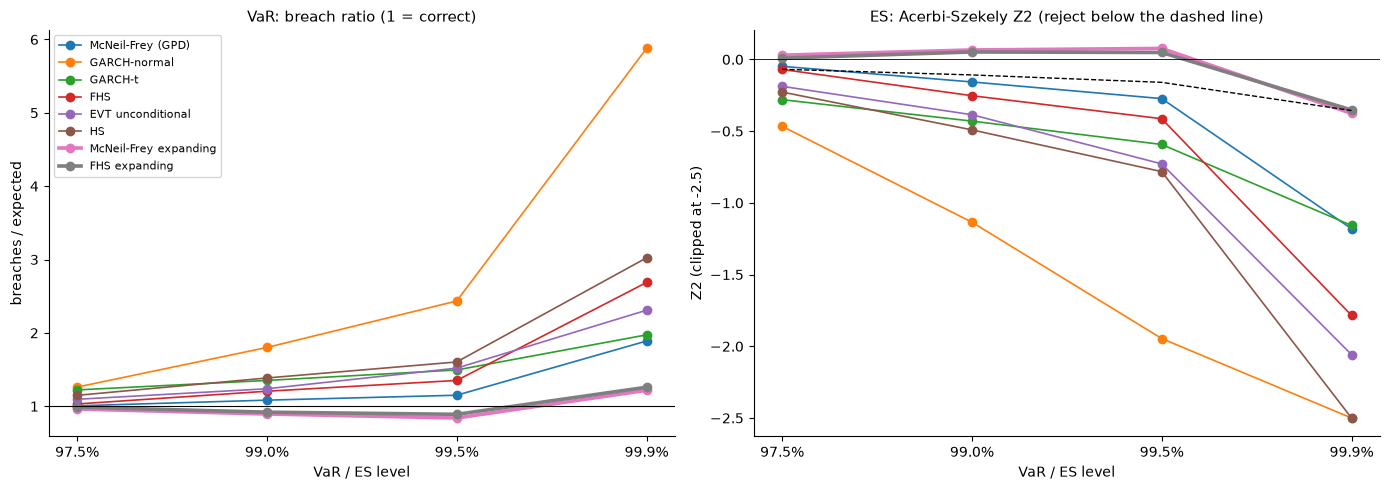

Methods passing all three tests, by level:
  97.5%: ['McNeil-Frey expanding', 'FHS expanding']
  99.0%: none
  99.5%: ['FHS expanding']
  99.9%: none


In [ ]:
# 9.5 Chart: backtest summary of all eight methods
exp_methods = ["McNeil-Frey expanding", "FHS expanding"]
bt_all = pd.concat([bt, bt2.loc[(slice(None), exp_methods), :]]).sort_index(level=0, sort_remaining=False)
bt_all.to_csv(OUT / "backtest_table_all.csv")

fig = plot_backtest_summary(bt_all, z2_crit, highlight=exp_methods)
fig.savefig(FIGURES / "backtest_summary.png", dpi=150, bbox_inches="tight")
plt.show()

print("Methods passing all three tests, by level:")
for q in LEVELS:
    ok = bt_all.loc[q].index[bt_all.loc[q, "pass all"]].tolist()
    print(f"  {q:.1%}: {ok if ok else 'none'}")

### 9.6 99.9% VaR through 1987, 2008 and 2020

| | |
|---|---|
| **1. What do I need to determine?** | How do the forecasts behave in the three great crises? |
| **2. What information and assumptions do I have?** | Daily losses and four 99.9% VaR forecasts. |
| **3. Which method is appropriate?** | Losses (bars) against VaR (lines); breaches per crisis window. |
| **4. Why should the method work?** | A good conditional VaR rises fast after the first shock; an unconditional one cannot. |
| **5. How can I verify the answer?** | About 0.1 breaches expected per window. |

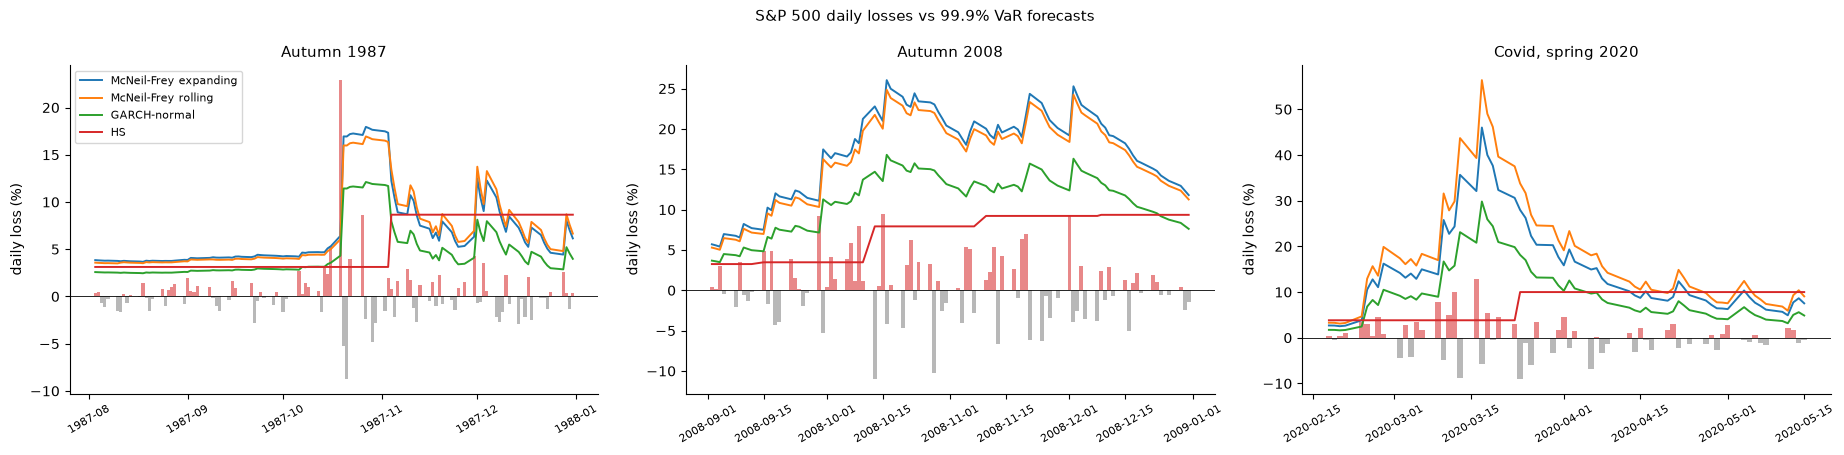

99.9% breaches in each crisis window (expected about 0.1 per window):
                    days  McNeil-Frey expanding  McNeil-Frey rolling  GARCH-normal  HS
Autumn 1987          106                      1                    2             3   4
Autumn 2008           85                      0                    0             1  11
Covid, spring 2020    63                      0                    0             1   7


In [ ]:
# 9.6 Chart: 99.9% VaR through 1987, 2008 and 2020
q = 0.999
lines = {"McNeil-Frey expanding": exp_oos[("McNeil-Frey expanding", "VaR", q)],
         "McNeil-Frey rolling": oos[("McNeil-Frey (GPD)", "VaR", q)],
         "GARCH-normal": oos[("GARCH-normal", "VaR", q)],
         "HS": oos[("HS", "VaR", q)]}
crises = [("1987-08-01", "1987-12-31", "Autumn 1987"), ("2008-09-01", "2008-12-31", "Autumn 2008"),
          ("2020-02-15", "2020-05-15", "Covid, spring 2020")]
fig = plot_var_through_crises(x_oos, lines, crises, "S&P 500 daily losses vs 99.9% VaR forecasts")
fig.savefig(FIGURES / "var_through_crises.png", dpi=150, bbox_inches="tight")
plt.show()

rows = {}
for a, b, lab in crises:
    l = x_oos.loc[a:b]
    rows[lab] = {"days": len(l), **{m: int((l > v.loc[a:b]).sum()) for m, v in lines.items()}}
print("99.9% breaches in each crisis window (expected about 0.1 per window):")
print(pd.DataFrame(rows).T.to_string())

**Findings – Section 9 (backtests, diagnosis, fix).** With a 1,000-day window, **McNeil–Frey is the best method up to 99.5%** (breach ratios 1.01 / 1.08 / 1.15, passes Kupiec at all three; Christoffersen only at 99.5%) but **no method passes at 99.9%**. The diagnosis: the 99.9% breaches are calm-market shocks (3.5–16σ, median σ lower than average), not unstable GARCH fits; in a calm decade the 1,000-day residual tail is too thin (99.9% multiplier 3.73σ in 1946–86). **The fix — rolling volatility, expanding residual tail** — raises the multiplier to 4.95σ in 1946–86 and cuts the 99.9% breaches from **45 to 29** (expected 23.8): Kupiec p = 0.30, Christoffersen p = 0.57, Z2 = −0.376 just below its critical value −0.356 (ES slightly too low). McNeil–Frey expanding passes all three tests at 97.5% and FHS expanding at 97.5% and 99.5%. In the crises the expanding McNeil–Frey breaches **once in autumn 1987 (the crash itself), and never in 2008 or 2020**, where historical simulation breaches 11 and 7 times.

## 10. Conclusions

**Question:** how large can a one-day loss on the S&P 500 be at 99.9% and beyond, and which model forecasts it reliably out of sample?

**Data.** S&P 500 price index, 24,818 daily losses from January 1928 to October 2026, after the removal of four data errors found by a volatility-scaled reversal rule (two passes).

**Main findings**

1. **The tail is fat but not extreme:** GPD above 2% gives **ξ = 0.19 ± 0.08** (α ≈ 5); Hill gives 0.29–0.35 but is biased upwards in this sample. The normal underestimates the 99.9% VaR by half and the ES by 60%.
2. **Unconditional extreme risk:** VaR 99.9% = **7.4%**, ES 99.9% = **10.0%** (95% interval for the VaR 6.8–8.1%). The **once-in-100-years daily loss is about 17% (95% interval 13.6–21.8%)**; 19 October 1987 (22.9% log loss) is a once-in-400-years event under the GPD, not an impossible one.
3. **Uncertainty grows fast beyond the data:** the interval for the 100-year loss is ±25% wide and asymmetric; use the profile likelihood or a block bootstrap, not the delta method.
4. **Extremes cluster** (extremal index 0.5): a GJR-GARCH filter removes the clustering (Ljung–Box 12,201 → 25) but not the fat tail (residual ξ = 0.21) — the case for McNeil–Frey.
5. **McNeil–Frey with a 1,000-day window works up to 99.5% but fails at 99.9%** (45 breaches vs 23.8), because a calm window contains no extreme residual.
6. **Rolling volatility + expanding residual tail fixes it:** 29 breaches at 99.9%, Kupiec and Christoffersen passed, ES borderline (Z2 −0.376 vs −0.356); zero breaches in 2008 and 2020.

**Recommendation**

- Daily VaR/ES at 99–99.9%: **McNeil–Frey with GJR-GARCH volatility re-estimated on a rolling window and the residual tail estimated on all available history.**
- Stress and capital beyond the data (10–100 years): the **unconditional GPD** with **profile-likelihood intervals**, reporting the interval and not only the point estimate.
- Never the normal for tail risk; avoid a Student-t fitted by MLE for ES (45% too high at 99.9%).

**Limitations.** One index (no portfolio, no dependence between assets); the threshold choice is a judgement (results stable between 1.5% and 3%); the 99.9% ES remains slightly too low; old data may contain further, smaller errors; the price index excludes dividends; GARCH parameters are refitted every 20 days, not daily.